# Sri Lanka Landslide Susceptibility — Modelling and Evaluation

This notebook trains and evaluates machine-learning models using the **Sri Lanka landslide susceptibility dataset** created in the dataset-builder notebook.

The modelling workflow is intentionally separated from data construction so that the original inventory, pseudo-absence generation, raster sampling, statistical tests, and preprocessing remain reproducible.

## Modelling workflow

0. Build the train/test split and preprocessing pipeline from `training_table_sri_lanka_kerala_factors.csv` (skipped automatically if already built).
1. Load the modelling-ready train/test data and reproducibility metadata.
2. Verify dataset integrity and visualize class balance.
3. Compare several baseline classifiers using **5-fold stratified cross-validation on the training set only**.
4. Tune Random Forest and XGBoost using the training set.
5. Select the final candidate using cross-validation performance — **not the held-out test set**.
6. Evaluate tuned models once on the held-out test set using multiple metrics.
7. Visualize confusion matrices, ROC/PR curves, calibration, and learning behaviour.
8. Interpret the selected model using permutation importance and optional SHAP analysis.
9. Perform **spatial cross-validation** as a robustness check against spatial autocorrelation.
11. Save the selected model, preprocessor, and evaluation results.

> The held-out test set is reserved for final evaluation. Model selection and hyperparameter tuning are performed using the training data only.

## 0. Setup

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
)
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold,
    cross_validate,
    RandomizedSearchCV,
    learning_curve,
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    brier_score_loss,
)

from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
    print("XGBoost:", xgb.__version__)
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost is not installed. XGBoost-specific cells will be skipped.")
    print("Install once if needed: pip install xgboost")

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_SPLITS = 5
np.random.seed(RANDOM_STATE)

print("Setup complete.")

XGBoost: 3.0.0
Setup complete.


## 0.1 Build the Sri Lanka train/test split and preprocessor

The Kerala dataset-builder notebook does the train/test split, scaling, and
one-hot encoding itself and hands this modelling notebook ready-made
`X_train_processed.csv`, `preprocessor.pkl`, etc.

The Sri Lanka dataset-builder notebook (`07i_Add_Kerala_Factors_Sri_Lanka.ipynb`)
stops one step earlier -- it produces `training_table_sri_lanka_kerala_factors.csv`
with every conditioning factor sampled, but no split/preprocessing yet. This cell
creates that split once, using **all** available Sri Lanka factors: the 13 that
match Kerala (terrain x7, soil x4, landcover, geology) plus the extra ones Kerala's
dataset doesn't have (`dist_to_river`, `dist_to_road`, five rainfall windows).

If you'd rather model on an *exact* Kerala-matched feature set for a fair
cross-country comparison, drop the "extra" columns from `continuous_factor_columns`
below before running.

If the split files already exist on disk, this cell reuses them so re-running the
notebook doesn't silently reshuffle your train/test rows.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import joblib as _joblib

_PROJECT_ROOT = Path.cwd().resolve().parent
_PROCESSED_DIR = _PROJECT_ROOT / "data" / "processed"

_FINAL_CSV = _PROCESSED_DIR / "training_table_sri_lanka_kerala_factors.csv"
_MANIFEST_PATH = _PROCESSED_DIR / "sri_lanka_kerala_factors_manifest.json"

_SPLIT_FILES = [
    "sri_lanka_X_train_raw.csv", "sri_lanka_X_test_raw.csv", "sri_lanka_y_train.csv", "sri_lanka_y_test.csv",
    "sri_lanka_X_train_processed.csv", "sri_lanka_X_test_processed.csv", "sri_lanka_preprocessor.pkl",
]

if all((_PROCESSED_DIR / f).exists() for f in _SPLIT_FILES):
    print("Train/test split and preprocessor already exist -- reusing them as-is.")
else:
    if not _FINAL_CSV.exists():
        raise FileNotFoundError(
            f"{_FINAL_CSV} not found. Run 07i_Add_Kerala_Factors_Sri_Lanka.ipynb first."
        )

    sl_full = pd.read_csv(_FINAL_CSV)

    # Kerala-matched factors + Sri Lanka's extra continuous factors
    _kerala_matched_continuous = [
        "elev", "slope", "aspect", "planc", "profc", "twi", "spi",
        "clay", "sand", "soc", "bdod",
    ]
    _extra_sl_continuous = [
        "dist_to_river", "dist_to_road",
        "rain_1d", "rain_3d", "rain_7d", "rain_15d", "rain_30d",
    ]
    continuous_factor_columns = [
        c for c in (_kerala_matched_continuous + _extra_sl_continuous)
        if c in sl_full.columns
    ]
    categorical_factor_columns = [c for c in ["landcover", "geologi"] if c in sl_full.columns]
    model_factor_columns = continuous_factor_columns + categorical_factor_columns

    print("Continuous factors:", continuous_factor_columns)
    print("Categorical factors:", categorical_factor_columns)

    model_df_prep = sl_full[["label"] + model_factor_columns + ["x", "y"]].dropna(
        subset=model_factor_columns
    ).reset_index(drop=True)

    print(f"\nRows before dropna: {len(sl_full):,} | after dropna: {len(model_df_prep):,}")
    print(model_df_prep["label"].value_counts())

    _X = model_df_prep[model_factor_columns + ["x", "y"]]
    _y = model_df_prep["label"].astype(int)

    _X_train_raw, _X_test_raw, y_train, y_test = train_test_split(
        _X, _y, test_size=0.20, stratify=_y, random_state=RANDOM_STATE
    )

    # X/Y (uppercase) aliases so downstream spatial-CV cells (written for Kerala's
    # UTM X/Y column names) work unchanged when reading X_train_raw.csv later.
    X_train_raw = _X_train_raw[model_factor_columns].copy()
    X_test_raw = _X_test_raw[model_factor_columns].copy()

    _transformers = []
    if continuous_factor_columns:
        _transformers.append(("continuous", StandardScaler(), continuous_factor_columns))
    if categorical_factor_columns:
        _transformers.append((
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_factor_columns,
        ))

    preprocessor = ColumnTransformer(_transformers)
    _X_train_processed = preprocessor.fit_transform(X_train_raw)
    _X_test_processed = preprocessor.transform(X_test_raw)

    _feature_names = preprocessor.get_feature_names_out()
    X_train = pd.DataFrame(
        _X_train_processed.toarray() if hasattr(_X_train_processed, "toarray") else _X_train_processed,
        columns=_feature_names,
    )
    X_test = pd.DataFrame(
        _X_test_processed.toarray() if hasattr(_X_test_processed, "toarray") else _X_test_processed,
        columns=_feature_names,
    )

    X_train_raw.to_csv(_PROCESSED_DIR / "sri_lanka_X_train_raw.csv", index=False)
    X_test_raw.to_csv(_PROCESSED_DIR / "sri_lanka_X_test_raw.csv", index=False)
    y_train.to_csv(_PROCESSED_DIR / "sri_lanka_y_train.csv", index=False)
    y_test.to_csv(_PROCESSED_DIR / "sri_lanka_y_test.csv", index=False)
    X_train.to_csv(_PROCESSED_DIR / "sri_lanka_X_train_processed.csv", index=False)
    X_test.to_csv(_PROCESSED_DIR / "sri_lanka_X_test_processed.csv", index=False)
    _joblib.dump(preprocessor, _PROCESSED_DIR / "sri_lanka_preprocessor.pkl")

    # Update the manifest so Section 1.2 picks up the right factor lists.
    _manifest = {}
    if _MANIFEST_PATH.exists():
        _manifest = json.loads(_MANIFEST_PATH.read_text(encoding="utf-8"))
    _manifest["continuous_factors"] = continuous_factor_columns
    _manifest["categorical_factors"] = categorical_factor_columns
    _MANIFEST_PATH.write_text(json.dumps(_manifest, indent=2), encoding="utf-8")

    # Static ESA WorldCover legend, for parity with the Kerala dataset builder.
    _worldcover_legend_path = _PROCESSED_DIR / "sri_lanka_worldcover_class_legend.csv"
    if not _worldcover_legend_path.exists():
        pd.DataFrame([
            {"landcover": 10, "class_name": "Tree cover"},
            {"landcover": 20, "class_name": "Shrubland"},
            {"landcover": 30, "class_name": "Grassland"},
            {"landcover": 40, "class_name": "Cropland"},
            {"landcover": 50, "class_name": "Built-up"},
            {"landcover": 60, "class_name": "Bare / sparse vegetation"},
            {"landcover": 70, "class_name": "Snow and ice"},
            {"landcover": 80, "class_name": "Permanent water bodies"},
            {"landcover": 90, "class_name": "Herbaceous wetland"},
            {"landcover": 95, "class_name": "Mangroves"},
            {"landcover": 100, "class_name": "Moss and lichen"},
        ]).to_csv(_worldcover_legend_path, index=False)

    print("\nSaved train/test split, preprocessor, and updated manifest to:", _PROCESSED_DIR)
    print("Processed feature count:", X_train.shape[1])


Train/test split and preprocessor already exist -- reusing them as-is.


## 1. Load modelling data and metadata

In [3]:
PROJECT_ROOT = Path.cwd().resolve().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Thesis-ready figure export folder
FIGURE_DIR = PROCESSED_DIR / "figures" / "sri_lanka_modeling"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Processed train/test matrices created by the dataset-builder notebook
X_train = pd.read_csv(PROCESSED_DIR / "sri_lanka_X_train_processed.csv")
X_test = pd.read_csv(PROCESSED_DIR / "sri_lanka_X_test_processed.csv")
y_train = pd.read_csv(PROCESSED_DIR / "sri_lanka_y_train.csv").squeeze("columns")
y_test = pd.read_csv(PROCESSED_DIR / "sri_lanka_y_test.csv").squeeze("columns")

# Raw factor matrices are required for leakage-safe spatial cross-validation
X_train_raw = pd.read_csv(PROCESSED_DIR / "sri_lanka_X_train_raw.csv")
X_test_raw = pd.read_csv(PROCESSED_DIR / "sri_lanka_X_test_raw.csv")

preprocessor = joblib.load(PROCESSED_DIR / "sri_lanka_preprocessor.pkl")

FINAL_CSV = PROCESSED_DIR / "training_table_sri_lanka_kerala_factors.csv"
MANIFEST_PATH = PROCESSED_DIR / "sri_lanka_kerala_factors_manifest.json"
GEOLOGY_LEGEND_PATH = PROCESSED_DIR / "sri_lanka_geology_legend.csv"
WORLDCOVER_LEGEND_PATH = PROCESSED_DIR / "sri_lanka_worldcover_class_legend.csv"

manifest = {}
if MANIFEST_PATH.exists():
    manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))

geology_legend = (
    pd.read_csv(GEOLOGY_LEGEND_PATH)
    if GEOLOGY_LEGEND_PATH.exists()
    else pd.DataFrame()
)

worldcover_legend = (
    pd.read_csv(WORLDCOVER_LEGEND_PATH)
    if WORLDCOVER_LEGEND_PATH.exists()
    else pd.DataFrame()
)


sns.set_theme(style="whitegrid", context="notebook")


PRIMARY = "#1F4E79"       # deep academic blue
SECONDARY = "#2E7D6E"     # dark teal
ACCENT = "#B7791F"        # muted gold
DANGER = "#A63D40"        # deep research red
SLATE = "#44546A"         # blue-gray
PURPLE = "#6A4C93"        # dark purple
ORANGE = "#C65D24"        # burnt orange
GREEN = "#3A6B35"         # forest green
PINK = "#9A4D6A"          # muted dark rose
CYAN = "#28788A"          # dark cyan

LIGHT = "#F7F8FA"
GRID = "#D5DAE0"

CLASS_COLORS = {
    "Non-landslide": "#2F5597",   # dark blue
    "Landslide": "#C43C3C",       # strong dark red
}

MODEL_COLORS = [
    "#1F4E79",   # blue
    "#2E7D6E",   # teal
    "#6A4C93",   # purple
    "#C65D24",   # orange
    "#A63D40",   # red
    "#28788A",   # cyan
    "#3A6B35",   # green
    "#9A4D6A",   # rose
]


plt.rcParams.update({

    "figure.dpi": 130,
    "savefig.dpi": 300,

    "figure.facecolor": "white",
    "axes.facecolor": "white",

    "axes.titlesize": 14,
    "axes.titleweight": "bold",

    "axes.labelsize": 11,

    "axes.edgecolor": "#94A3B8",
    "axes.linewidth": 0.9,

    "grid.color": GRID,
    "grid.alpha": 0.60,
    "grid.linewidth": 0.7,

    "legend.frameon": False,

    "font.size": 10.5,
})


def polish_axes(
    ax,
    title=None,
    xlabel=None,
    ylabel=None
):

    if title:
        ax.set_title(
            title,
            loc="left",
            pad=14
        )

    if xlabel is not None:
        ax.set_xlabel(xlabel)

    if ylabel is not None:
        ax.set_ylabel(ylabel)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_axisbelow(True)

    return ax




def save_figure(fig, filename):
    path = FIGURE_DIR / filename
    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )
    print("Saved figure:", path)
    return path

print("Project root :", PROJECT_ROOT)
print("Processed dir:", PROCESSED_DIR)
print("Figure dir   :", FIGURE_DIR)
print()
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)
print("Raw train:", X_train_raw.shape)
print("Raw test :", X_test_raw.shape)
print("Processed features:", X_train.shape[1])


Project root : D:\PROJECTS\Landslide_prediction
Processed dir: D:\PROJECTS\Landslide_prediction\data\processed
Figure dir   : D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling

X_train: (1169, 28) | y_train: (1169,)
X_test : (293, 28) | y_test : (293,)
Raw train: (1169, 20)
Raw test : (293, 20)
Processed features: 28


### 1.1 Data integrity and class-balance check

Missing values in processed train: 0
Missing values in processed test : 0


,Train,Test
Non-landslide,584,147
Landslide,585,146


Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\01_class_balance.png


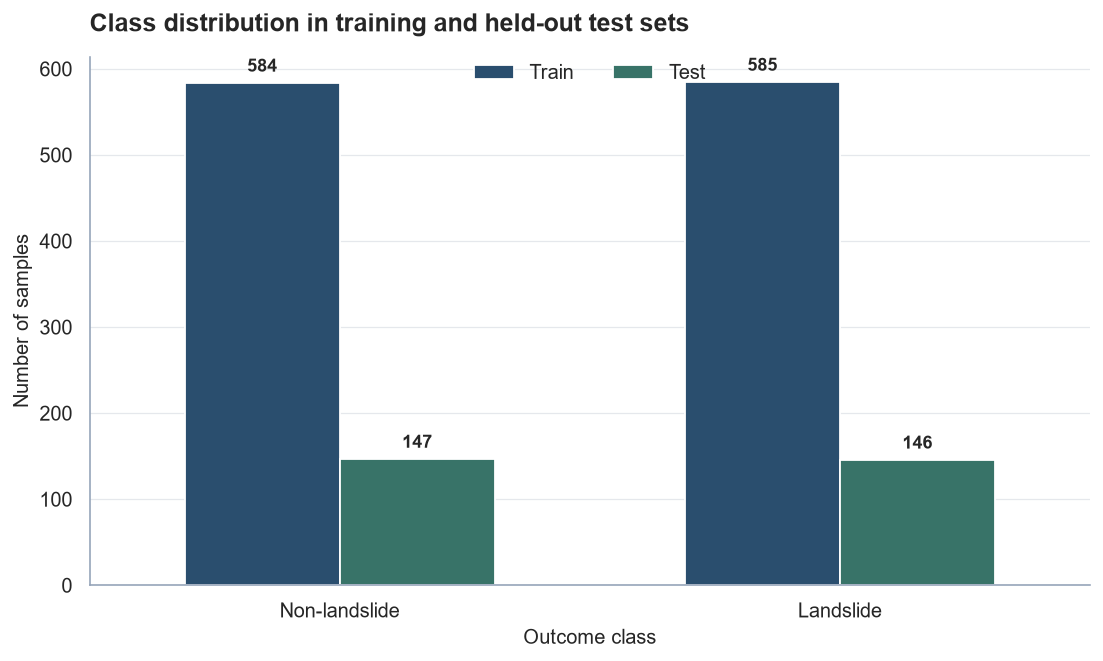

In [4]:
assert len(X_train) == len(y_train), "X_train/y_train row mismatch."
assert len(X_test) == len(y_test), "X_test/y_test row mismatch."
assert list(X_train.columns) == list(X_test.columns), "Processed train/test columns differ."
assert list(X_train_raw.columns) == list(X_test_raw.columns), "Raw train/test columns differ."

print("Missing values in processed train:", int(X_train.isna().sum().sum()))
print("Missing values in processed test :", int(X_test.isna().sum().sum()))

class_summary = pd.DataFrame({
    "Train": y_train.value_counts().sort_index(),
    "Test": y_test.value_counts().sort_index(),
}).fillna(0).astype(int)

class_summary.index = [
    "Non-landslide" if i == 0 else "Landslide"
    for i in class_summary.index
]

display(class_summary)

plot_df = (
    class_summary
    .reset_index(names="Class")
    .melt(id_vars="Class", var_name="Dataset", value_name="Samples")
)

fig, ax = plt.subplots(figsize=(8.6, 5.2))
sns.barplot(
    data=plot_df,
    x="Class",
    y="Samples",
    hue="Dataset",
    palette=[PRIMARY, SECONDARY],
    width=0.62,
    ax=ax,
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=4, fontsize=10, fontweight="bold")

polish_axes(
    ax,
    "Class distribution in training and held-out test sets",
    "Outcome class",
    "Number of samples",
)
ax.legend(title="", ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.02))
ax.grid(axis="x", visible=False)

fig.tight_layout()
save_figure(fig, "01_class_balance.png")
plt.show()


### 1.2 Conditioning-factor summary

,Factor type,Count
0,Continuous,11
1,Categorical,2


Continuous factors : ['elev', 'slope', 'aspect', 'planc', 'profc', 'twi', 'spi', 'clay', 'sand', 'soc', 'bdod']
Categorical factors: ['landcover', 'geologi']
Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\02_factor_family_summary.png


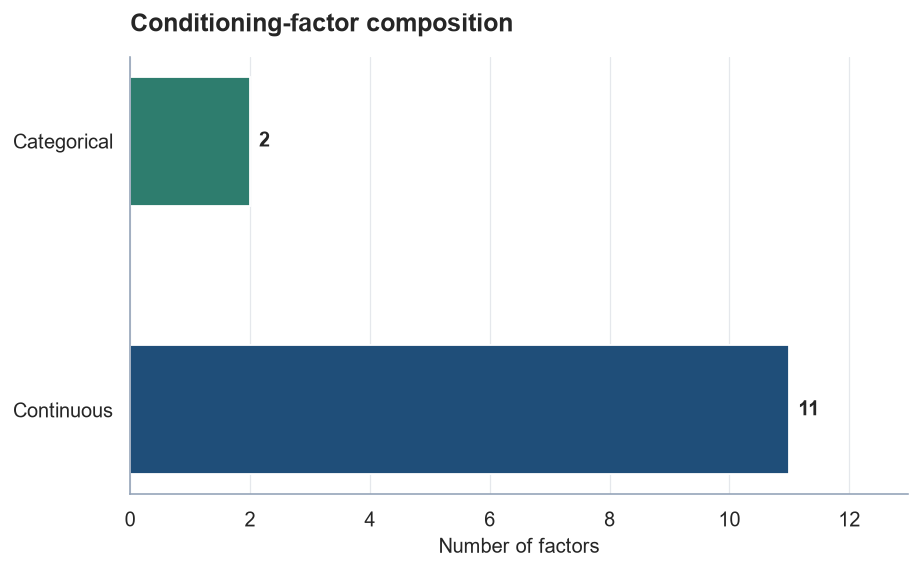

In [5]:
continuous_factors = manifest.get(
    "continuous_factors",
    [c for c in X_train_raw.columns if c not in {"landcover", "geologi"}]
)

categorical_factors = manifest.get(
    "categorical_factors",
    [c for c in ["landcover", "geologi"] if c in X_train_raw.columns]
)

factor_family_summary = pd.DataFrame({
    "Factor type": ["Continuous", "Categorical"],
    "Count": [len(continuous_factors), len(categorical_factors)],
})

display(factor_family_summary)

print("Continuous factors :", continuous_factors)
print("Categorical factors:", categorical_factors)

fig, ax = plt.subplots(figsize=(7.2, 4.5))
bars = ax.barh(
    factor_family_summary["Factor type"],
    factor_family_summary["Count"],
    color=[PRIMARY, SECONDARY],
    height=0.48,
)

for bar in bars:
    ax.text(
        bar.get_width() + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width())}",
        va="center",
        fontsize=11,
        fontweight="bold",
    )

polish_axes(
    ax,
    "Conditioning-factor composition",
    "Number of factors",
    "",
)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(factor_family_summary["Count"]) * 1.18)

fig.tight_layout()
save_figure(fig, "02_factor_family_summary.png")
plt.show()


## 2. Baseline model comparison

All baseline models are compared using the **same 5-fold stratified cross-validation folds** on the training set.

The processed feature matrix is used here because it already applies the training-fitted scaling and categorical encoding created in the dataset-builder notebook.

The held-out test set is **not used** in this section.

In [6]:
candidate_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE,
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
    ),
    "SVM (RBF)": SVC(
        probability=True,
        random_state=RANDOM_STATE,
    ),
    "MLP (Neural Network)": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=800,
        random_state=RANDOM_STATE,
    ),
}

if XGBOOST_AVAILABLE:
    candidate_models["XGBoost"] = xgb.XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=1,
    )

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

cv_summary_rows = []
cv_fold_rows = []

for name, model in candidate_models.items():
    print(f"Running 5-fold CV: {name}")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1,
    )

    summary = {"model": name}

    for metric in scoring:
        summary[f"{metric}_mean"] = scores[f"test_{metric}"].mean()
        summary[f"{metric}_std"] = scores[f"test_{metric}"].std()

    summary["train_f1_mean"] = scores["train_f1"].mean()
    summary["f1_gap"] = summary["train_f1_mean"] - summary["f1_mean"]
    cv_summary_rows.append(summary)

    for fold in range(N_SPLITS):
        cv_fold_rows.append({
            "model": name,
            "fold": fold + 1,
            "accuracy": scores["test_accuracy"][fold],
            "precision": scores["test_precision"][fold],
            "recall": scores["test_recall"][fold],
            "f1": scores["test_f1"][fold],
            "roc_auc": scores["test_roc_auc"][fold],
        })

cv_results_df = (
    pd.DataFrame(cv_summary_rows)
    .sort_values("f1_mean", ascending=False)
    .reset_index(drop=True)
)

cv_fold_df = pd.DataFrame(cv_fold_rows)

display(cv_results_df.round(4))

Running 5-fold CV: Logistic Regression
Running 5-fold CV: Decision Tree
Running 5-fold CV: Random Forest
Running 5-fold CV: Gradient Boosting
Running 5-fold CV: SVM (RBF)
Running 5-fold CV: MLP (Neural Network)
Running 5-fold CV: XGBoost


,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,train_f1_mean,f1_gap
0,Random Forest,0.7400,0.0404,0.7242,0.0474,0.7812,0.0327,0.7509,0.0346,0.8051,0.0361,1.0000,0.2491
1,XGBoost,0.7151,0.0249,0.7053,0.0311,0.7436,0.0311,0.7233,0.0216,0.7929,0.0332,1.0000,0.2767
2,Gradient Boosting,0.7074,0.0311,0.6976,0.0364,0.7368,0.0147,0.7164,0.0250,0.7821,0.0245,0.9955,0.2791
3,SVM (RBF),0.6903,0.0360,0.6916,0.0394,0.6906,0.0615,0.6898,0.0408,0.7562,0.0297,0.7627,0.0729
4,MLP (Neural Network),0.6741,0.0346,0.6706,0.0422,0.6923,0.0216,0.6806,0.0267,0.7253,0.0419,1.0000,0.3194
5,Decision Tree,0.6638,0.0150,0.6558,0.0339,0.7060,0.0618,0.6767,0.0174,0.7013,0.0127,0.8726,0.1959
6,Logistic Regression,0.6630,0.0246,0.6679,0.0308,0.6547,0.0574,0.6594,0.0296,0.7329,0.0396,0.6886,0.0291


### Visualization standard

All modelling figures use a consistent thesis-ready visual style with readable typography, restrained colour use, direct metric annotation, and **300-DPI PNG export** to `data/processed/figures/sri_lanka_modeling/`.


### 2.1 Baseline-performance heatmap

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\03_baseline_cv_heatmap.png


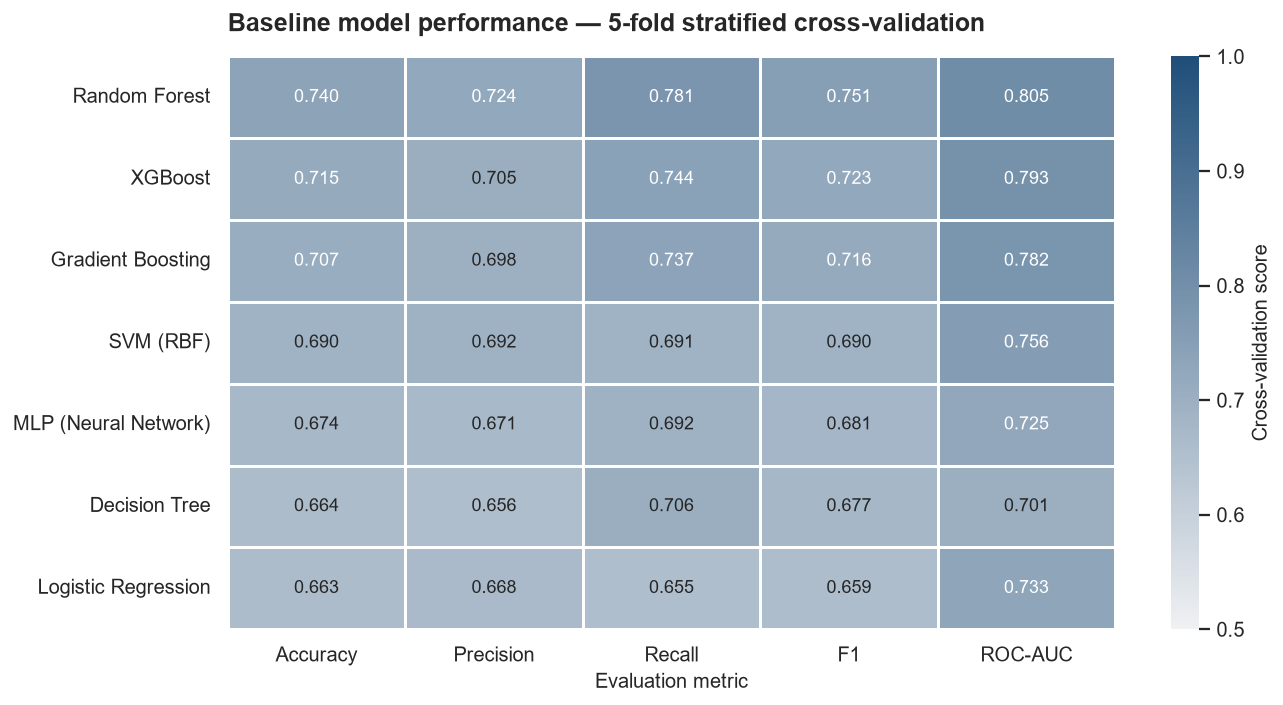

In [7]:
baseline_metrics = [
    "accuracy_mean",
    "precision_mean",
    "recall_mean",
    "f1_mean",
    "roc_auc_mean",
]

heatmap_df = (
    cv_results_df
    .set_index("model")[baseline_metrics]
    .rename(columns={
        "accuracy_mean": "Accuracy",
        "precision_mean": "Precision",
        "recall_mean": "Recall",
        "f1_mean": "F1",
        "roc_auc_mean": "ROC-AUC",
    })
)

fig, ax = plt.subplots(figsize=(10.5, max(4.6, 0.62 * len(heatmap_df) + 1.2)))
cmap = sns.light_palette(PRIMARY, as_cmap=True)

sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".3f",
    vmin=0.5,
    vmax=1.0,
    cmap=cmap,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "Cross-validation score"},
    annot_kws={"fontsize": 10},
    ax=ax,
)

ax.set_title("Baseline model performance — 5-fold stratified cross-validation", loc="left", pad=14, fontweight="bold")
ax.set_xlabel("Evaluation metric")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()
save_figure(fig, "03_baseline_cv_heatmap.png")
plt.show()


### 2.2 Fold-to-fold stability

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\04_cv_f1_stability.png


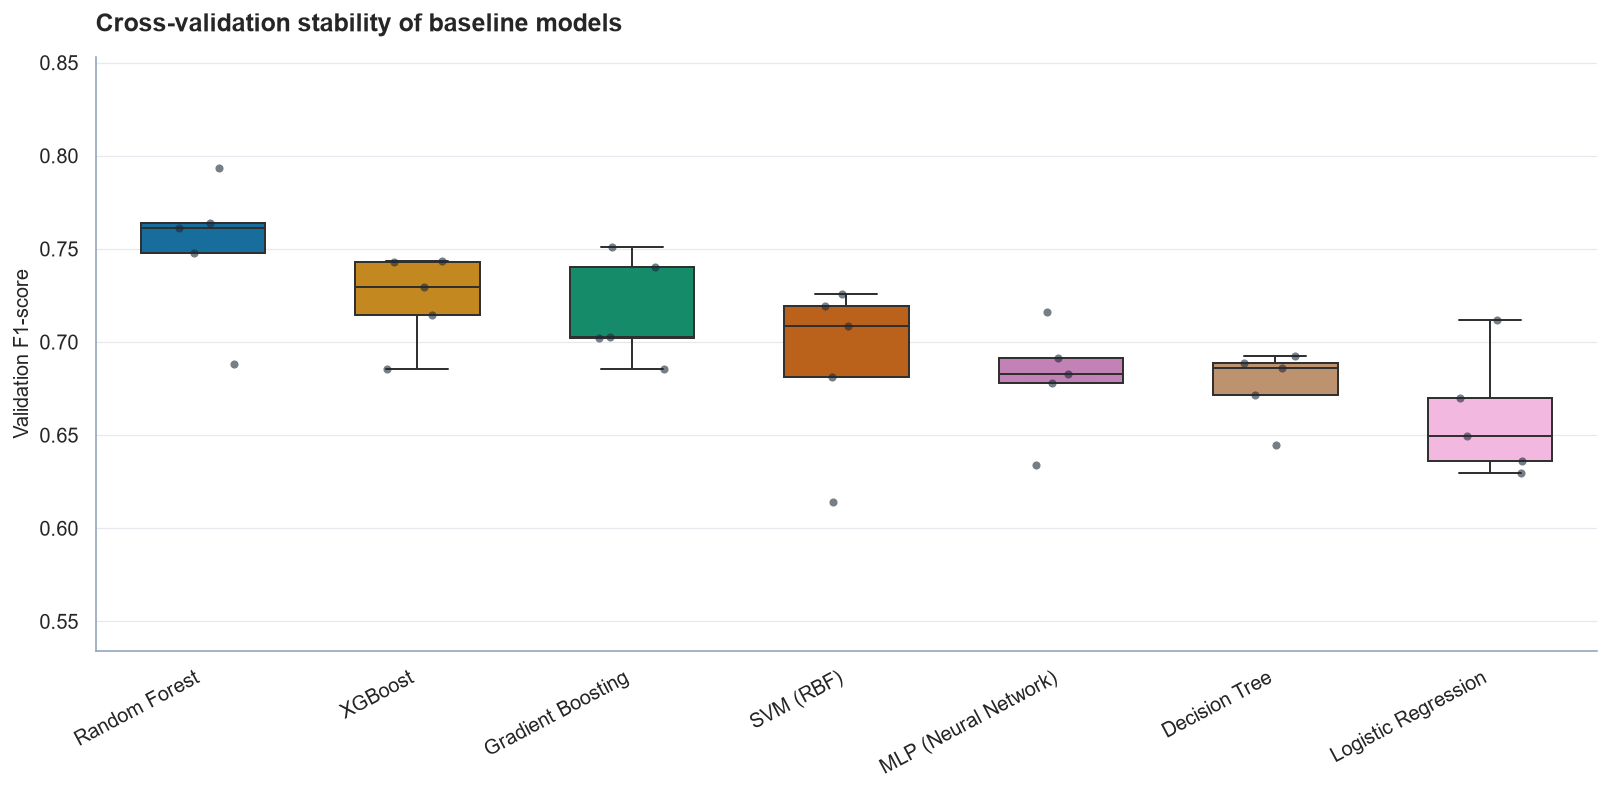

In [8]:
model_order = (
    cv_results_df
    .sort_values("f1_mean", ascending=False)["model"]
    .tolist()
)

model_palette = dict(
    zip(
        model_order,
        sns.color_palette("colorblind", n_colors=len(model_order))
    )
)

fig, ax = plt.subplots(figsize=(12.5, 6.2))

sns.boxplot(
    data=cv_fold_df,
    x="model",
    y="f1",
    order=model_order,
    palette=model_palette,
    width=0.58,
    linewidth=1.1,
    fliersize=0,
    ax=ax,
)

sns.stripplot(
    data=cv_fold_df,
    x="model",
    y="f1",
    order=model_order,
    color="#1F2937",
    size=4.5,
    alpha=0.6,
    jitter=0.16,
    ax=ax,
)

polish_axes(
    ax,
    "Cross-validation stability of baseline models",
    "",
    "Validation F1-score",
)
ax.set_ylim(max(0, cv_fold_df["f1"].min() - 0.08), min(1.0, cv_fold_df["f1"].max() + 0.06))
ax.tick_params(axis="x", rotation=28)
for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

fig.tight_layout()
save_figure(fig, "04_cv_f1_stability.png")
plt.show()


### 2.3 Training-versus-validation F1 gap

,model,train_f1_mean,f1_mean,f1_gap
6,MLP (Neural Network),1.0000,0.6806,0.3194
5,Gradient Boosting,0.9955,0.7164,0.2791
4,XGBoost,1.0000,0.7233,0.2767
3,Random Forest,1.0000,0.7509,0.2491
2,Decision Tree,0.8726,0.6767,0.1959
1,SVM (RBF),0.7627,0.6898,0.0729
0,Logistic Regression,0.6886,0.6594,0.0291


Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\05_training_validation_gap.png


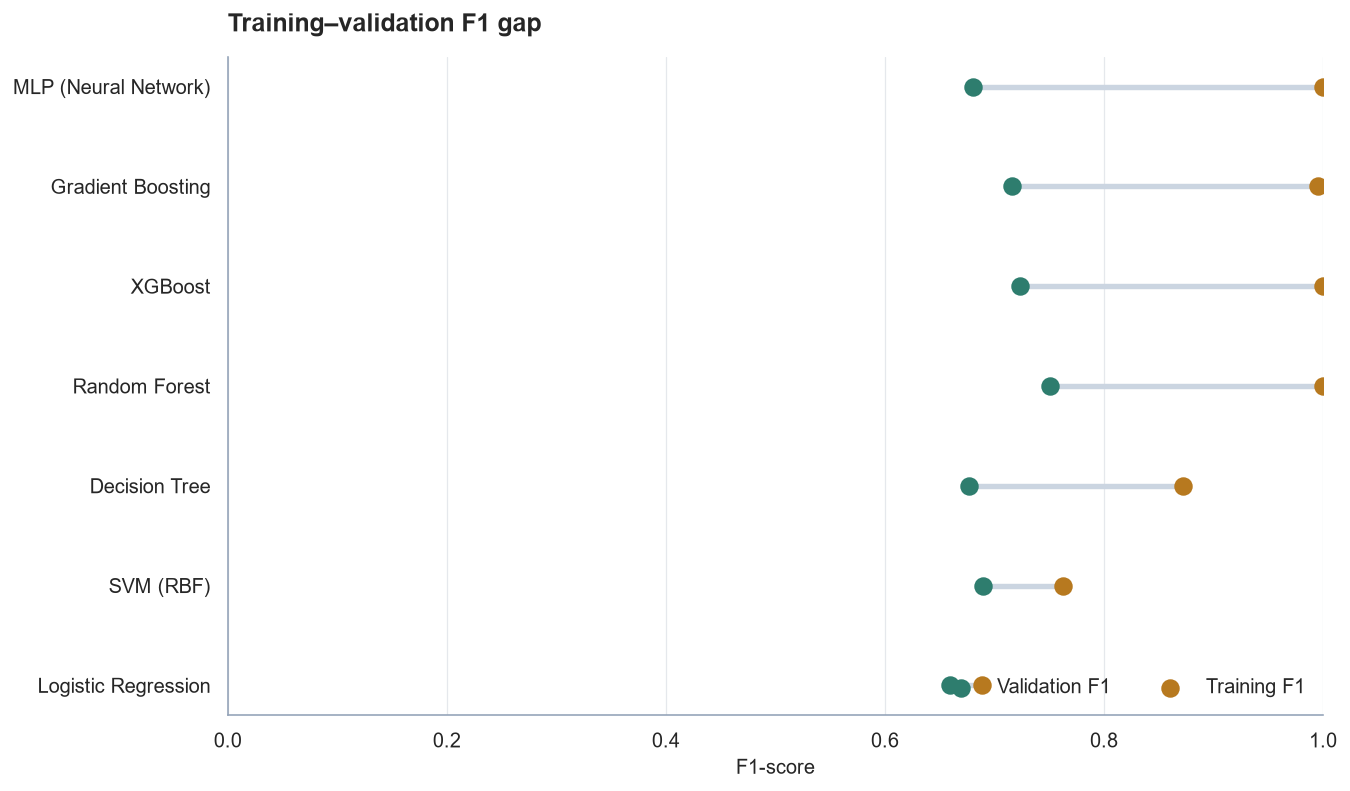

In [9]:
gap_df = (
    cv_results_df[
        ["model", "train_f1_mean", "f1_mean", "f1_gap"]
    ]
    .sort_values("f1_gap", ascending=True)
    .reset_index(drop=True)
)

display(gap_df.sort_values("f1_gap", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(10.5, 6.2))
y_pos = np.arange(len(gap_df))

for i, row in gap_df.iterrows():
    ax.plot(
        [row["f1_mean"], row["train_f1_mean"]],
        [i, i],
        color="#CBD5E1",
        linewidth=3,
        zorder=1,
    )

ax.scatter(
    gap_df["f1_mean"],
    y_pos,
    s=85,
    color=SECONDARY,
    label="Validation F1",
    zorder=3,
)
ax.scatter(
    gap_df["train_f1_mean"],
    y_pos,
    s=85,
    color=ACCENT,
    label="Training F1",
    zorder=3,
)

ax.set_yticks(y_pos)
ax.set_yticklabels(gap_df["model"])
ax.set_xlim(0, 1)

polish_axes(
    ax,
    "Training–validation F1 gap",
    "F1-score",
    "",
)
ax.legend(loc="lower right", ncol=2)
ax.grid(axis="y", visible=False)

fig.tight_layout()
save_figure(fig, "05_training_validation_gap.png")
plt.show()


## 3. Hyperparameter tuning

Random Forest and XGBoost are tuned using `RandomizedSearchCV` on the training set.

The optimization metric is **F1-score**, which balances precision and recall for the binary landslide/non-landslide task.

In [10]:
# Random Forest tuning

rf_param_dist = {
    "n_estimators": [200, 300, 500, 800],
    "max_depth": [None, 8, 12, 16, 24],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None],
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    param_distributions=rf_param_dist,
    n_iter=25,
    scoring="f1",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)

rf_search.fit(X_train, y_train)

print("Best RF parameters:")
print(rf_search.best_params_)
print("Best RF CV F1:", round(rf_search.best_score_, 4))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best RF parameters:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 12}
Best RF CV F1: 0.7519


In [11]:
# XGBoost tuning

xgb_search = None

if XGBOOST_AVAILABLE:
    xgb_param_dist = {
        "n_estimators": [200, 300, 500, 800],
        "max_depth": [3, 4, 6, 8, 10],
        "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
        "subsample": [0.6, 0.8, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "min_child_weight": [1, 3, 5],
    }

    xgb_search = RandomizedSearchCV(
        estimator=xgb.XGBClassifier(
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=1,
        ),
        param_distributions=xgb_param_dist,
        n_iter=25,
        scoring="f1",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1,
        return_train_score=True,
    )

    xgb_search.fit(X_train, y_train)

    print("Best XGBoost parameters:")
    print(xgb_search.best_params_)
    print("Best XGBoost CV F1:", round(xgb_search.best_score_, 4))
else:
    print("XGBoost tuning skipped because xgboost is not installed.")

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best XGBoost parameters:
{'subsample': 0.8, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.8}
Best XGBoost CV F1: 0.7385


### 3.1 Select the final candidate using training CV only

,Model,Best CV F1
1,Random Forest (tuned),0.7519
0,XGBoost (tuned),0.7385


Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\06_tuned_model_selection.png


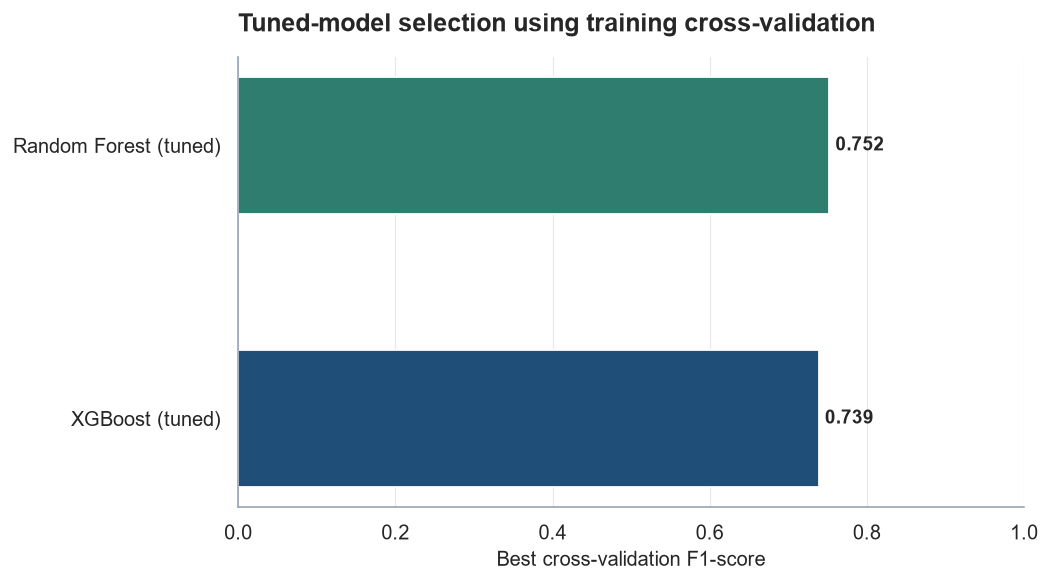

Selected final candidate: Random Forest (tuned)
Selection criterion: highest training cross-validation F1.


In [12]:
tuned_models = {
    "Random Forest (tuned)": rf_search.best_estimator_,
}

tuned_cv_f1 = {
    "Random Forest (tuned)": rf_search.best_score_,
}

if xgb_search is not None:
    tuned_models["XGBoost (tuned)"] = xgb_search.best_estimator_
    tuned_cv_f1["XGBoost (tuned)"] = xgb_search.best_score_

selected_name = max(
    tuned_cv_f1,
    key=tuned_cv_f1.get,
)

selected_model = tuned_models[selected_name]

selection_df = (
    pd.DataFrame({
        "Model": list(tuned_cv_f1.keys()),
        "Best CV F1": list(tuned_cv_f1.values()),
    })
    .sort_values("Best CV F1", ascending=True)
    .reset_index(drop=True)
)

display(selection_df.sort_values("Best CV F1", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(8.2, 4.6))
colors = [
    SECONDARY if model == selected_name else PRIMARY
    for model in selection_df["Model"]
]
bars = ax.barh(
    selection_df["Model"],
    selection_df["Best CV F1"],
    color=colors,
    height=0.5,
)

for bar, value in zip(bars, selection_df["Best CV F1"]):
    ax.text(
        value + 0.008,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        fontweight="bold",
    )

polish_axes(
    ax,
    "Tuned-model selection using training cross-validation",
    "Best cross-validation F1-score",
    "",
)
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)

fig.tight_layout()
save_figure(fig, "06_tuned_model_selection.png")
plt.show()

print("Selected final candidate:", selected_name)
print("Selection criterion: highest training cross-validation F1.")


## 4. Held-out test evaluation

The held-out test set is now used **for the first time** to estimate final predictive performance.

In addition to accuracy, the notebook reports precision, recall/sensitivity, specificity, F1, MCC, TSS, ROC-AUC, and PR-AUC.

In [13]:
def evaluate_binary_classifier(model, X, y):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y, y_pred, labels=[0, 1]).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan
    tss = sensitivity + specificity - 1

    return {
        "accuracy": accuracy_score(y, y_pred),
        "precision": precision_score(y, y_pred, zero_division=0),
        "recall": recall_score(y, y_pred, zero_division=0),
        "specificity": specificity,
        "f1": f1_score(y, y_pred, zero_division=0),
        "mcc": matthews_corrcoef(y, y_pred),
        "tss": tss,
        "roc_auc": roc_auc_score(y, y_proba),
        "pr_auc": average_precision_score(y, y_proba),
        "brier": brier_score_loss(y, y_proba),
    }


test_rows = []

for name, model in tuned_models.items():
    result = evaluate_binary_classifier(
        model,
        X_test,
        y_test,
    )
    result["model"] = name
    test_rows.append(result)

final_results_df = (
    pd.DataFrame(test_rows)
    .set_index("model")
    .sort_values("f1", ascending=False)
)

display(final_results_df.round(4))

print("\nFinal candidate selected BEFORE test evaluation:", selected_name)
print("\nClassification report:")
print(
    classification_report(
        y_test,
        selected_model.predict(X_test),
        target_names=["Non-landslide", "Landslide"],
        digits=4,
    )
)

,accuracy,precision,recall,specificity,f1,mcc,tss,roc_auc,pr_auc,brier
model,,,,,,,,,,
Random Forest (tuned),0.7065,0.6807,0.7740,0.6395,0.7244,0.4171,0.4134,0.7798,0.7842,0.1961
XGBoost (tuned),0.6826,0.6497,0.7877,0.5782,0.7121,0.3741,0.3659,0.7695,0.7735,0.1987



Final candidate selected BEFORE test evaluation: Random Forest (tuned)

Classification report:
               precision    recall  f1-score   support

Non-landslide     0.7402    0.6395    0.6861       147
    Landslide     0.6807    0.7740    0.7244       146

     accuracy                         0.7065       293
    macro avg     0.7104    0.7067    0.7052       293
 weighted avg     0.7105    0.7065    0.7052       293



### 4.1 Held-out metric heatmap

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\07_heldout_metric_heatmap.png


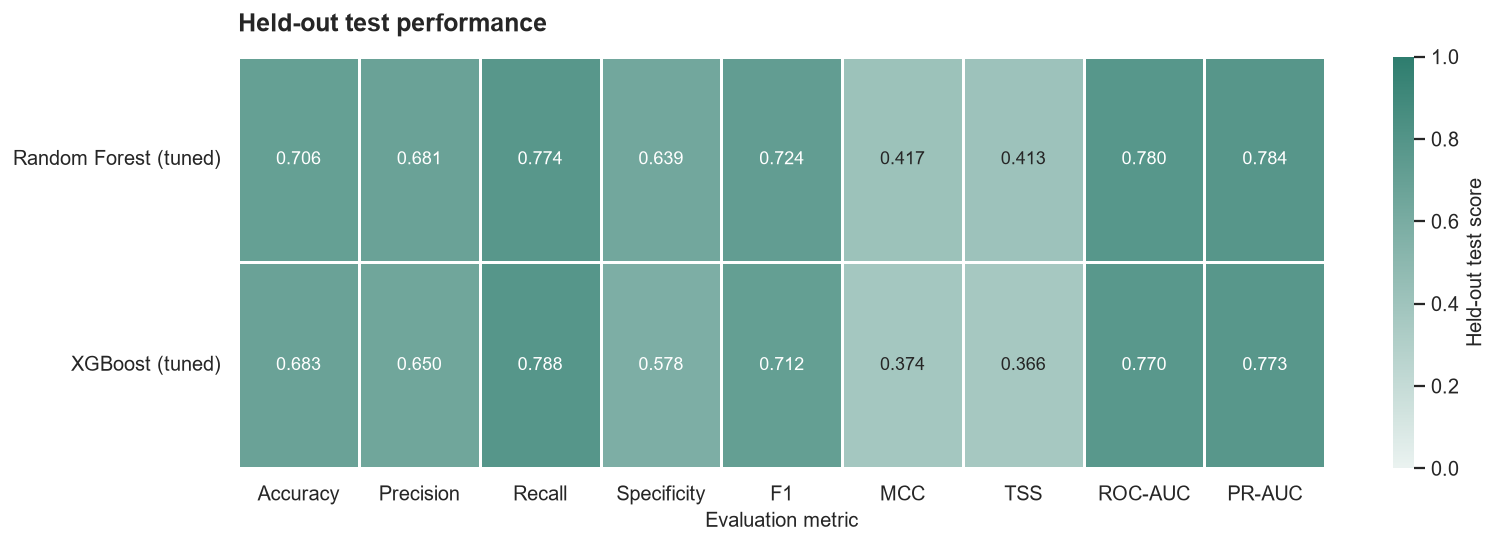

In [14]:
metric_cols = [
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "mcc",
    "tss",
    "roc_auc",
    "pr_auc",
]

metric_labels = {
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "specificity": "Specificity",
    "f1": "F1",
    "mcc": "MCC",
    "tss": "TSS",
    "roc_auc": "ROC-AUC",
    "pr_auc": "PR-AUC",
}

heldout_plot = final_results_df[metric_cols].rename(columns=metric_labels)

fig, ax = plt.subplots(figsize=(12.5, max(4.3, 1.25 * len(heldout_plot) + 1.2)))
cmap = sns.light_palette(SECONDARY, as_cmap=True)

sns.heatmap(
    heldout_plot,
    annot=True,
    fmt=".3f",
    vmin=0,
    vmax=1,
    cmap=cmap,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "Held-out test score"},
    annot_kws={"fontsize": 10},
    ax=ax,
)

ax.set_title("Held-out test performance", loc="left", pad=14, fontweight="bold")
ax.set_xlabel("Evaluation metric")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()
save_figure(fig, "07_heldout_metric_heatmap.png")
plt.show()


### 4.2 Confusion matrices

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\08_confusion_matrices.png


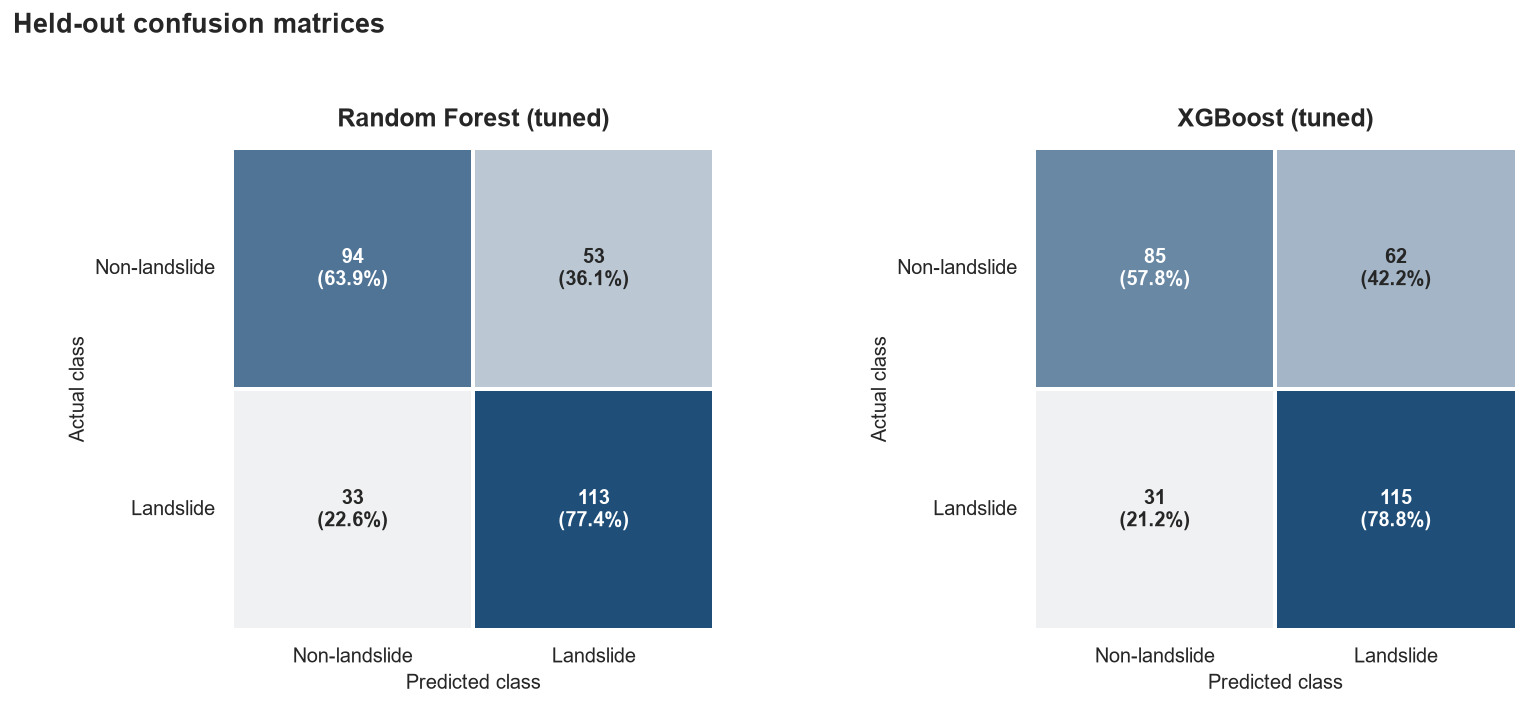

In [15]:
n_models = len(tuned_models)

fig, axes = plt.subplots(
    1,
    n_models,
    figsize=(6.3 * n_models, 5.5),
)

axes = np.atleast_1d(axes)

for ax, (name, model) in zip(axes, tuned_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    # Row-normalized percentages for easier interpretation
    row_pct = cm / cm.sum(axis=1, keepdims=True)
    labels = np.array([
        [f"{cm[i, j]:,}\n({row_pct[i, j]:.1%})" for j in range(2)]
        for i in range(2)
    ])

    sns.heatmap(
        cm,
        annot=labels,
        fmt="",
        cmap=sns.light_palette(PRIMARY, as_cmap=True),
        cbar=False,
        linewidths=1.2,
        linecolor="white",
        square=True,
        xticklabels=["Non-landslide", "Landslide"],
        yticklabels=["Non-landslide", "Landslide"],
        annot_kws={"fontsize": 11, "fontweight": "bold"},
        ax=ax,
    )

    ax.set_title(name, pad=12, fontweight="bold")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle(
    "Held-out confusion matrices",
    x=0.02,
    ha="left",
    fontsize=15,
    fontweight="bold",
)
fig.tight_layout(rect=[0, 0, 1, 0.94])
save_figure(fig, "08_confusion_matrices.png")
plt.show()


### 4.3 ROC curves

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\08_roc_curves_Sri_Lanka.png


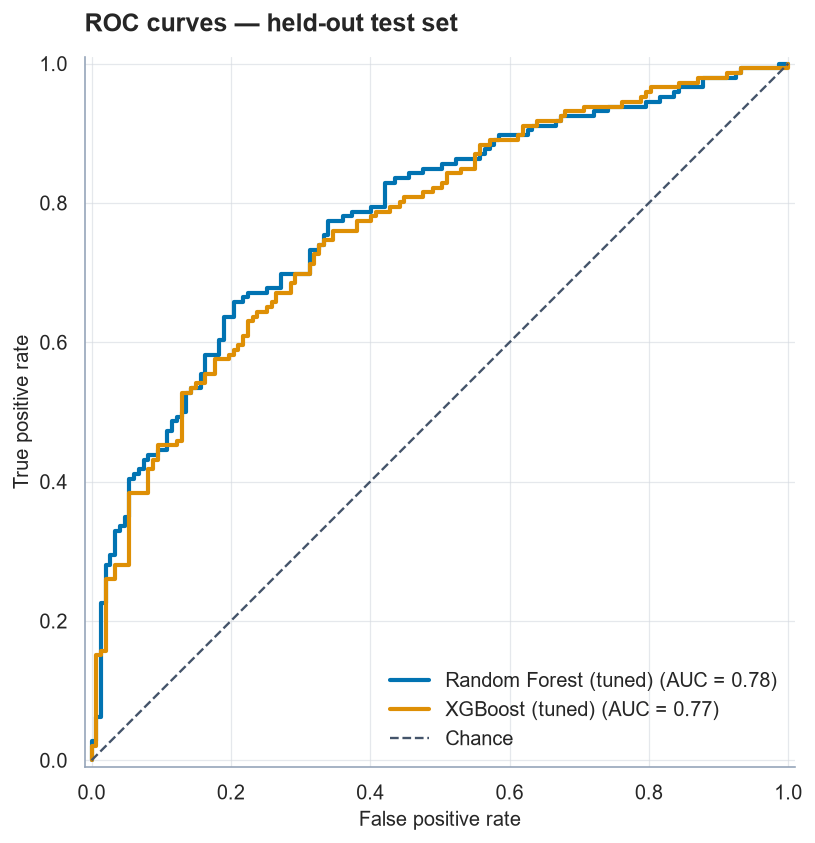

In [16]:
fig, ax = plt.subplots(figsize=(7.8, 6.6))

curve_colors = sns.color_palette("colorblind", n_colors=len(tuned_models))

for color, (name, model) in zip(curve_colors, tuned_models.items()):
    disp = RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        ax=ax,
        name=name,
    )
    disp.line_.set_color(color)
    disp.line_.set_linewidth(2.3)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--", linewidth=1.3, color=SLATE,
    label="Chance",
)

polish_axes(ax, "ROC curves — held-out test set", "False positive rate", "True positive rate")
ax.legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "08_roc_curves_Sri_Lanka.png")
plt.show()

### 4.4 Precision–Recall curves

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\10_precision_recall_curves_Sri_Lanka.png


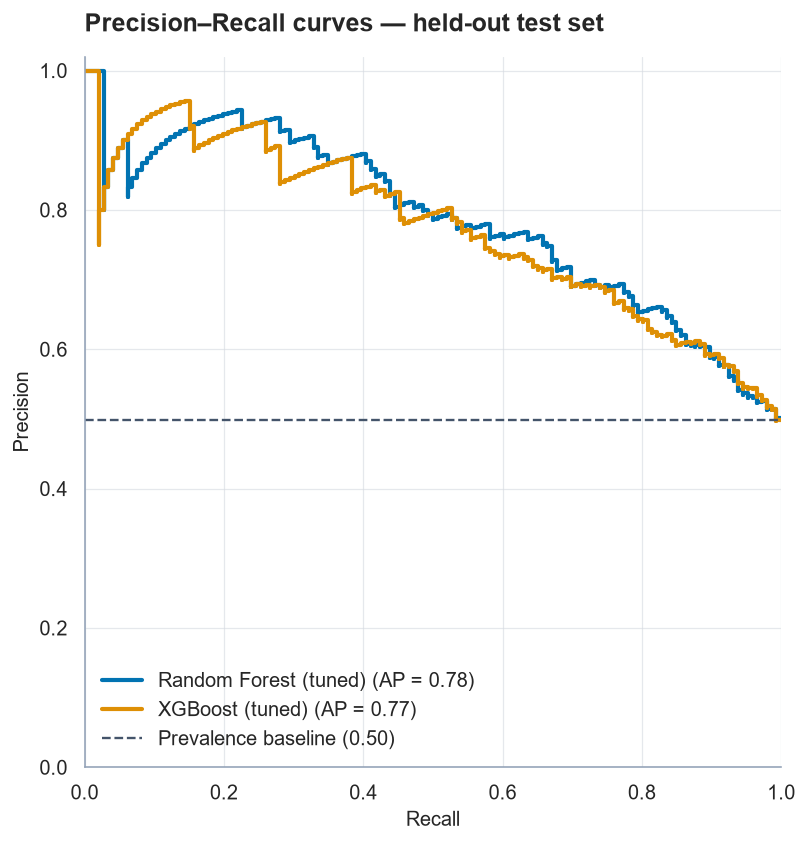

In [17]:
fig, ax = plt.subplots(figsize=(7.8, 6.6))

curve_colors = sns.color_palette("colorblind", n_colors=len(tuned_models))

for color, (name, model) in zip(curve_colors, tuned_models.items()):
    PrecisionRecallDisplay.from_estimator(
        model,
        X_test,
        y_test,
        ax=ax,
        name=name,
        color=color,
        linewidth=2.3,
    )

baseline_precision = float(np.mean(y_test))
ax.axhline(
    baseline_precision,
    linestyle="--",
    linewidth=1.3,
    color=SLATE,
    label=f"Prevalence baseline ({baseline_precision:.2f})",
)

polish_axes(
    ax,
    "Precision–Recall curves — held-out test set",
    "Recall",
    "Precision",
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower left")

fig.tight_layout()
save_figure(fig, "10_precision_recall_curves_Sri_Lanka.png")
plt.show()


### 4.5 Probability calibration of the selected model

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\11_calibration_curve.png


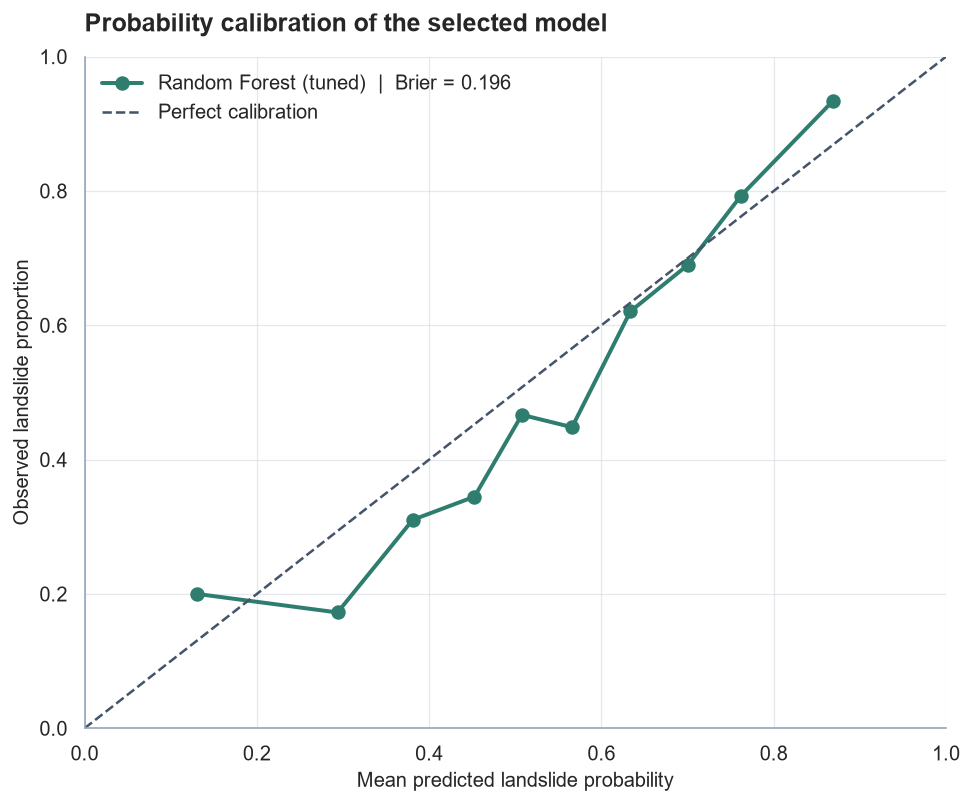

Brier score: 0.1961
Lower Brier scores indicate better probability calibration.


In [18]:
selected_proba = selected_model.predict_proba(X_test)[:, 1]

prob_true, prob_pred = calibration_curve(
    y_test,
    selected_proba,
    n_bins=10,
    strategy="quantile",
)

brier = brier_score_loss(y_test, selected_proba)

fig, ax = plt.subplots(figsize=(7.6, 6.3))
ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    markersize=7,
    linewidth=2.2,
    color=SECONDARY,
    label=f"{selected_name}  |  Brier = {brier:.3f}",
)
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.4,
    color=SLATE,
    label="Perfect calibration",
)

polish_axes(
    ax,
    "Probability calibration of the selected model",
    "Mean predicted landslide probability",
    "Observed landslide proportion",
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc="upper left")

fig.tight_layout()
save_figure(fig, "11_calibration_curve.png")
plt.show()

print("Brier score:", round(brier, 4))
print("Lower Brier scores indicate better probability calibration.")


### 4.6 Learning curve — sample-size and overfitting check

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\12_learning_curve_Sri_Lanka.png


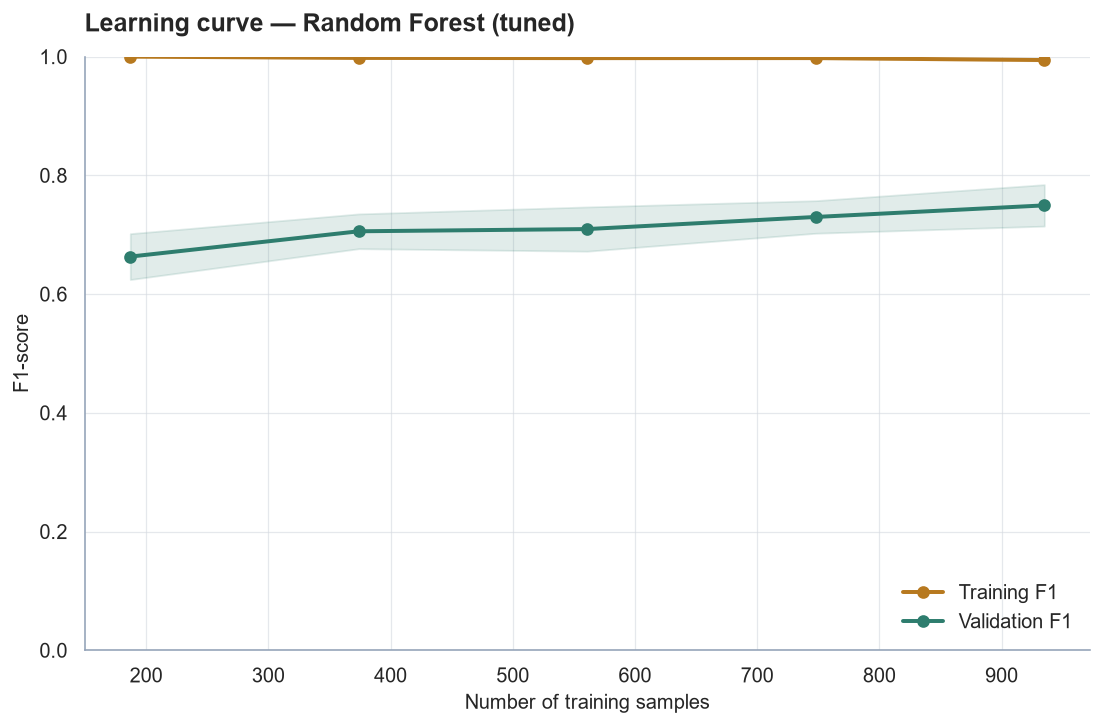

In [19]:
train_sizes, train_scores, valid_scores = learning_curve(
    estimator=clone(selected_model),
    X=X_train,
    y=y_train,
    cv=cv,
    scoring="f1",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1,
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
valid_mean = valid_scores.mean(axis=1)
valid_std = valid_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(8.6, 5.7))

ax.plot(
    train_sizes,
    train_mean,
    marker="o",
    markersize=6,
    linewidth=2.2,
    color=ACCENT,
    label="Training F1",
)
ax.plot(
    train_sizes,
    valid_mean,
    marker="o",
    markersize=6,
    linewidth=2.2,
    color=SECONDARY,
    label="Validation F1",
)

ax.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    color=ACCENT,
    alpha=0.14,
)
ax.fill_between(
    train_sizes,
    valid_mean - valid_std,
    valid_mean + valid_std,
    color=SECONDARY,
    alpha=0.14,
)

polish_axes(
    ax,
    f"Learning curve — {selected_name}",
    "Number of training samples",
    "F1-score",
)
ax.set_ylim(0, 1)
ax.legend(loc="lower right")

fig.tight_layout()
save_figure(fig, "12_learning_curve_Sri_Lanka.png")
plt.show()


## 5. Feature importance and model interpretation

Permutation importance is computed for every selected model type and is therefore used as the primary feature-importance measure.

Tree-based built-in importance and SHAP are included as complementary interpretation methods.

In [20]:
# Human-readable labels for one-hot encoded categorical features

worldcover_classes = {
    10: "Tree cover",
    20: "Shrubland",
    30: "Grassland",
    40: "Cropland",
    50: "Built-up",
    60: "Bare / sparse vegetation",
    70: "Snow and ice",
    80: "Permanent water",
    90: "Herbaceous wetland",
    95: "Mangroves",
    100: "Moss and lichen",
}

geology_classes = {}

if not geology_legend.empty:
    if {"geologi", "geology_name"}.issubset(geology_legend.columns):
        geology_classes = {
            int(code): name
            for code, name in zip(
                geology_legend["geologi"],
                geology_legend["geology_name"],
            )
        }


def pretty_feature_name(feature):
    name = str(feature)
    name = name.replace("num__", "")
    name = name.replace("cat__", "")

    land_match = re.search(r"landcover[_=](\d+(?:\.\d+)?)", name)
    if land_match:
        code = int(float(land_match.group(1)))
        return f"Landcover: {worldcover_classes.get(code, code)}"

    geo_match = re.search(r"geologi[_=](\d+(?:\.\d+)?)", name)
    if geo_match:
        code = int(float(geo_match.group(1)))
        return f"Geology: {geology_classes.get(code, code)}"

    return name


pretty_feature_names = [
    pretty_feature_name(c)
    for c in X_train.columns
]

print("Example processed feature labels:")
for original, pretty in list(zip(X_train.columns, pretty_feature_names))[:15]:
    print(f"{original}  ->  {pretty}")

Example processed feature labels:
continuous__elev  ->  continuous__elev
continuous__slope  ->  continuous__slope
continuous__aspect  ->  continuous__aspect
continuous__planc  ->  continuous__planc
continuous__profc  ->  continuous__profc
continuous__twi  ->  continuous__twi
continuous__spi  ->  continuous__spi
continuous__clay  ->  continuous__clay
continuous__sand  ->  continuous__sand
continuous__soc  ->  continuous__soc
continuous__bdod  ->  continuous__bdod
continuous__dist_to_river  ->  continuous__dist_to_river
continuous__dist_to_road  ->  continuous__dist_to_road
continuous__rain_1d  ->  continuous__rain_1d
continuous__rain_3d  ->  continuous__rain_3d


### 5.1 Permutation importance

,feature,display_feature,importance_mean,importance_std
0,continuous__elev,continuous__elev,0.0385,0.0184
1,continuous__rain_1d,continuous__rain_1d,0.0384,0.0084
2,continuous__rain_15d,continuous__rain_15d,0.0272,0.0121
3,continuous__rain_30d,continuous__rain_30d,0.0234,0.0071
4,continuous__dist_to_road,continuous__dist_to_road,0.0199,0.0082
5,continuous__rain_7d,continuous__rain_7d,0.0149,0.0106
6,continuous__rain_3d,continuous__rain_3d,0.0145,0.0104
7,continuous__slope,continuous__slope,0.0133,0.0129
8,continuous__dist_to_river,continuous__dist_to_river,0.0111,0.0112
9,continuous__soc,continuous__soc,0.0086,0.0098


Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\13_permutation_importance.png


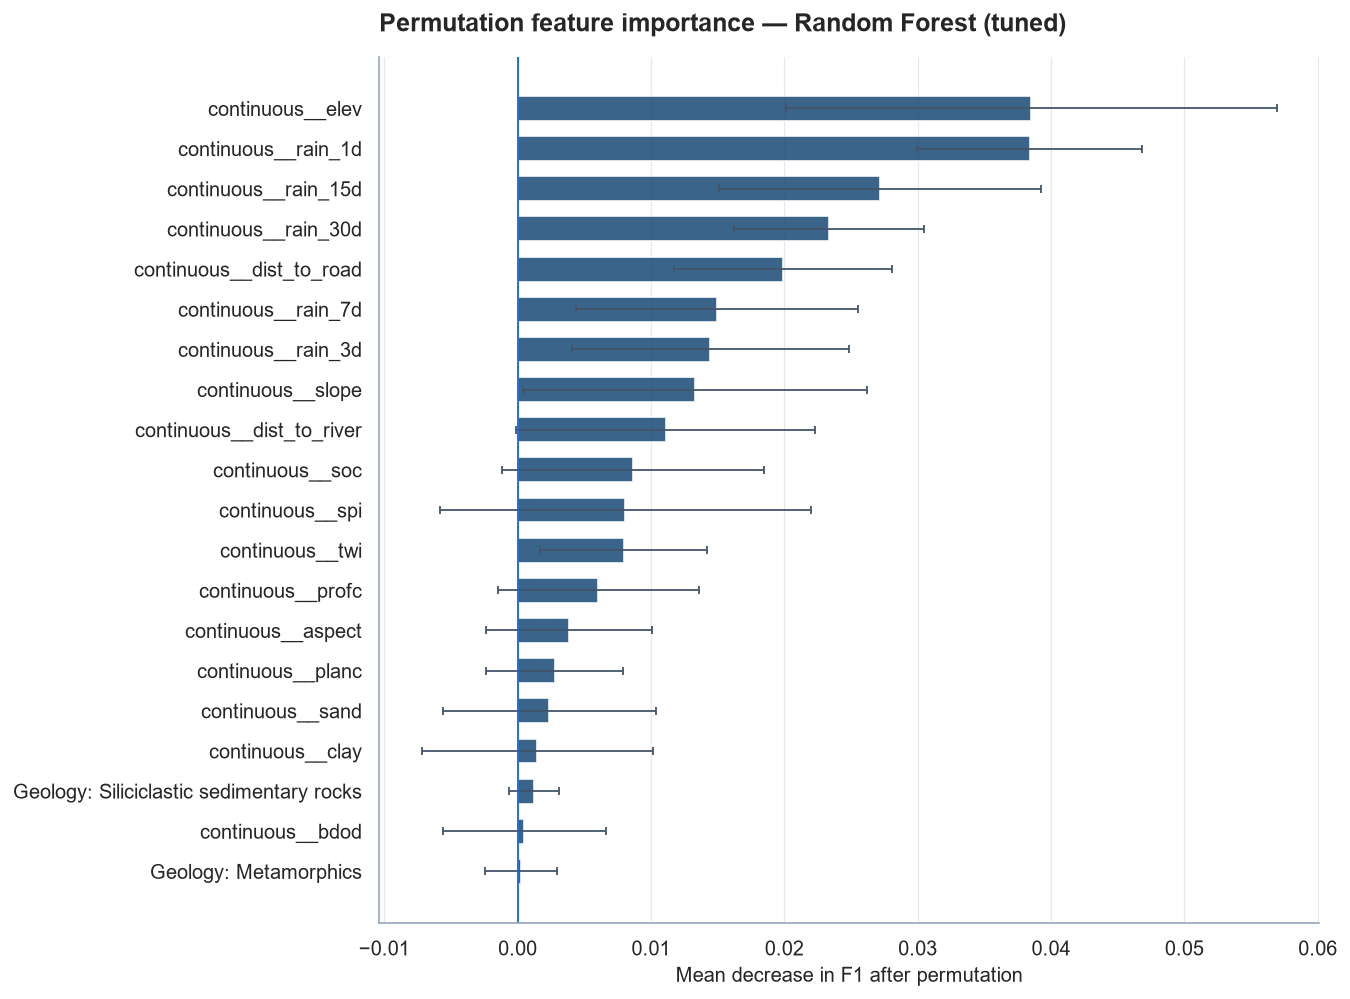

In [21]:
perm_result = permutation_importance(
    selected_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=20,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

perm_df = pd.DataFrame({
    "feature": X_test.columns,
    "display_feature": pretty_feature_names,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std,
})

perm_df = (
    perm_df
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

display(perm_df.head(20).round(4))

top_perm = perm_df.head(20).sort_values("importance_mean")

fig, ax = plt.subplots(figsize=(10.5, 7.8))
bars = ax.barh(
    top_perm["display_feature"],
    top_perm["importance_mean"],
    xerr=top_perm["importance_std"],
    color=PRIMARY,
    alpha=0.88,
    height=0.62,
    error_kw={"ecolor": SLATE, "capsize": 2, "elinewidth": 1},
)

polish_axes(
    ax,
    f"Permutation feature importance — {selected_name}",
    "Mean decrease in F1 after permutation",
    "",
)
ax.axvline(0, color="#1264D7", linewidth=1)
ax.grid(axis="y", visible=False)

fig.tight_layout()
save_figure(fig, "13_permutation_importance.png")
plt.show()


### 5.2 Built-in tree importance

,feature,display_feature,importance
0,continuous__elev,continuous__elev,0.0988
1,continuous__slope,continuous__slope,0.0820
6,continuous__spi,continuous__spi,0.0702
15,continuous__rain_7d,continuous__rain_7d,0.0612
9,continuous__soc,continuous__soc,0.0608
16,continuous__rain_15d,continuous__rain_15d,0.0543
14,continuous__rain_3d,continuous__rain_3d,0.0529
17,continuous__rain_30d,continuous__rain_30d,0.0515
12,continuous__dist_to_road,continuous__dist_to_road,0.0510
2,continuous__aspect,continuous__aspect,0.0476


Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\14_builtin_feature_importance.png


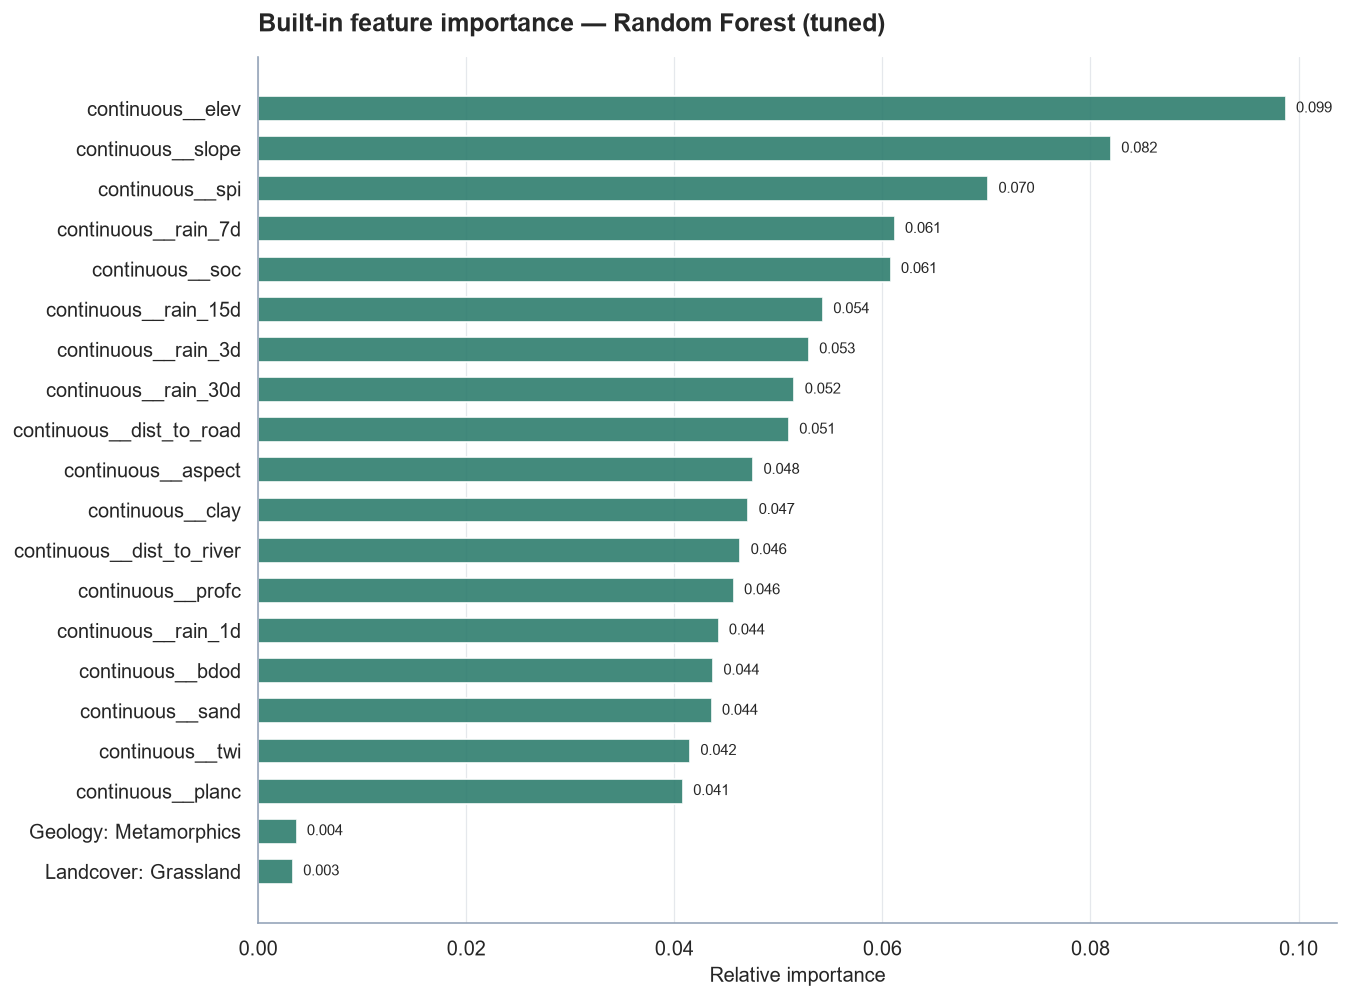

In [22]:
if hasattr(selected_model, "feature_importances_"):
    builtin_df = pd.DataFrame({
        "feature": X_train.columns,
        "display_feature": pretty_feature_names,
        "importance": selected_model.feature_importances_,
    }).sort_values("importance", ascending=False)

    display(builtin_df.head(20).round(4))

    top_builtin = builtin_df.head(20).sort_values("importance")

    fig, ax = plt.subplots(figsize=(10.5, 7.8))
    bars = ax.barh(
        top_builtin["display_feature"],
        top_builtin["importance"],
        color=SECONDARY,
        alpha=0.9,
        height=0.62,
    )

    for bar, value in zip(bars, top_builtin["importance"]):
        ax.text(
            value + top_builtin["importance"].max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            fontsize=8.5,
        )

    polish_axes(
        ax,
        f"Built-in feature importance — {selected_name}",
        "Relative importance",
        "",
    )
    ax.grid(axis="y", visible=False)

    fig.tight_layout()
    save_figure(fig, "14_builtin_feature_importance.png")
    plt.show()
else:
    print("The selected model does not provide built-in tree feature importance.")


### 5.3 Optional SHAP interpretation

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\15_shap_summary.png


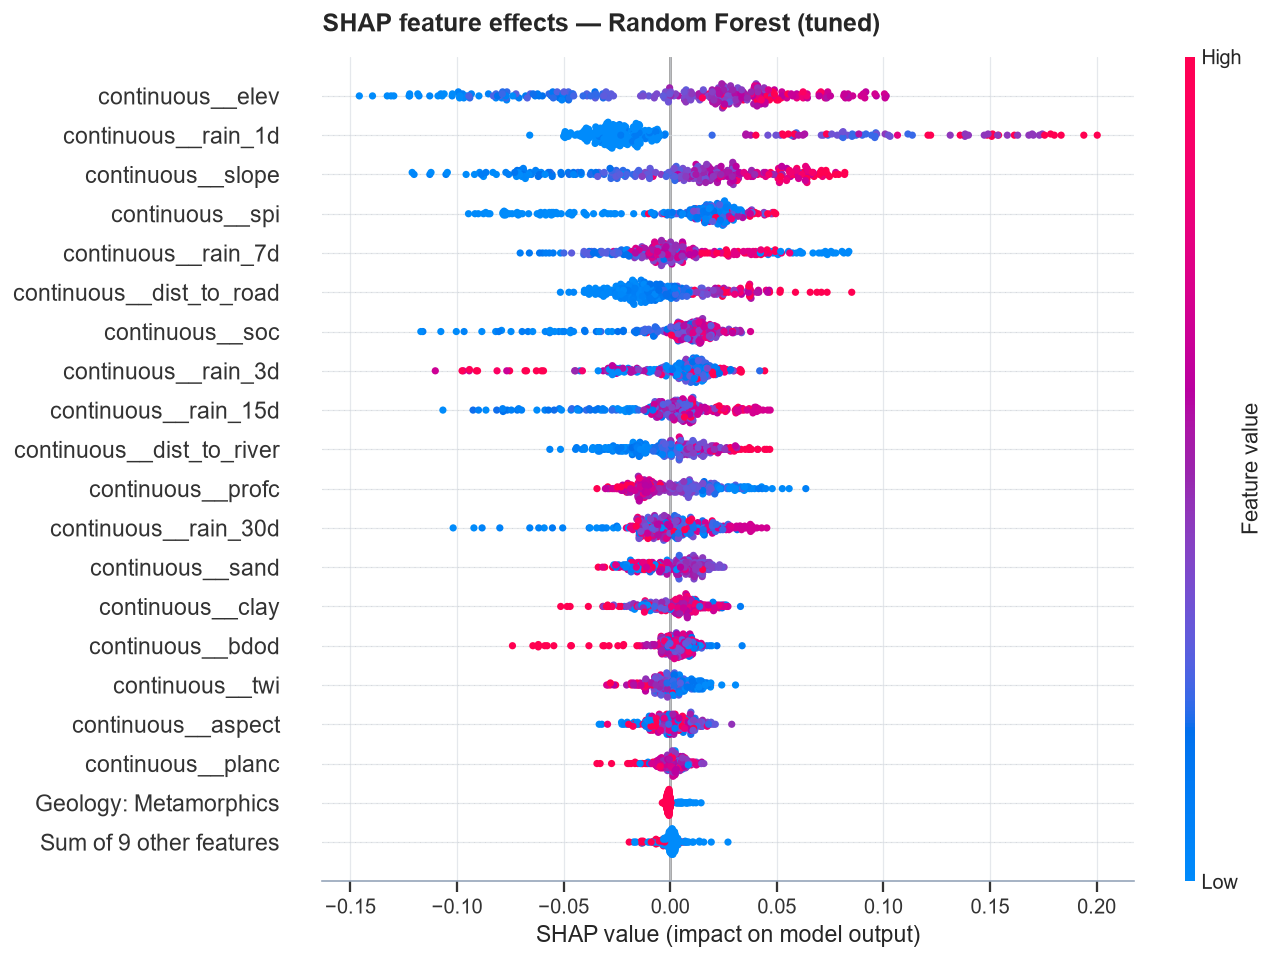

In [23]:
try:
    import shap

    if hasattr(selected_model, "feature_importances_"):
        X_shap = X_test.sample(
            n=min(1000, len(X_test)),
            random_state=RANDOM_STATE,
        )

        explainer = shap.TreeExplainer(selected_model)
        explanation = explainer(X_shap)

        # Binary Random Forest can return one SHAP array per class.
        if explanation.values.ndim == 3:
            explanation = explanation[:, :, 1]

        explanation.feature_names = pretty_feature_names

        shap.plots.beeswarm(
            explanation,
            max_display=20,
            show=False,
        )

        fig = plt.gcf()
        ax = plt.gca()
        ax.set_title(
            f"SHAP feature effects — {selected_name}",
            loc="left",
            pad=14,
            fontweight="bold",
        )
        fig.set_size_inches(10.5, 7.5)
        fig.tight_layout()
        save_figure(fig, "15_shap_summary.png")
        plt.show()

    else:
        print("SHAP TreeExplainer skipped because the selected model is not tree-based.")

except ImportError:
    print("SHAP is not installed. Install once if needed: pip install shap")
except Exception as e:
    print("SHAP plot could not be generated:", type(e).__name__, e)


## 6. Spatial cross-validation — robustness against spatial leakage

Random cross-validation can be optimistic when nearby samples share similar environmental conditions.

This section rebuilds modelling data from the final CSV, creates **10 km spatial blocks**, and compares:

- ordinary stratified random cross-validation, and
- stratified group cross-validation where entire spatial blocks are held out.

The preprocessor is **re-fitted inside every fold**, preventing preprocessing leakage.

In [24]:
if not FINAL_CSV.exists():
    raise FileNotFoundError(
        f"Final modelling CSV not found: {FINAL_CSV}"
    )

model_df = pd.read_csv(FINAL_CSV)

# Sri Lanka table uses lowercase x/y (UTM 44N metres); alias to X/Y so the
# rest of this section (written against Kerala's X/Y column names) works unchanged.
if "X" not in model_df.columns and "x" in model_df.columns:
    model_df["X"] = model_df["x"]
if "Y" not in model_df.columns and "y" in model_df.columns:
    model_df["Y"] = model_df["y"]

raw_feature_columns = X_train_raw.columns.tolist()

required_spatial_columns = (
    raw_feature_columns
    + ["X", "Y", "label"]
)

missing_required = [
    c for c in required_spatial_columns
    if c not in model_df.columns
]

if missing_required:
    raise ValueError(
        f"Missing columns required for spatial CV: {missing_required}"
    )

model_df = model_df.dropna(
    subset=required_spatial_columns
).reset_index(drop=True)

GRID_SIZE_M = 10_000

model_df["grid_x"] = (
    model_df["X"] // GRID_SIZE_M
).astype(int)

model_df["grid_y"] = (
    model_df["Y"] // GRID_SIZE_M
).astype(int)

model_df["spatial_block"] = (
    model_df["grid_x"].astype(str)
    + "_"
    + model_df["grid_y"].astype(str)
)

X_spatial_raw = model_df[raw_feature_columns]
y_spatial = model_df["label"].astype(int)
groups = model_df["spatial_block"]

print("Rows used for spatial CV:", len(model_df))
print("Spatial blocks:", groups.nunique())
print("Class balance:")
print(y_spatial.value_counts())

Rows used for spatial CV: 1462
Spatial blocks: 101
Class balance:
label
1    731
0    731
Name: count, dtype: int64


### 6.1 Visualize spatial folds

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\16_spatial_cv_folds.png


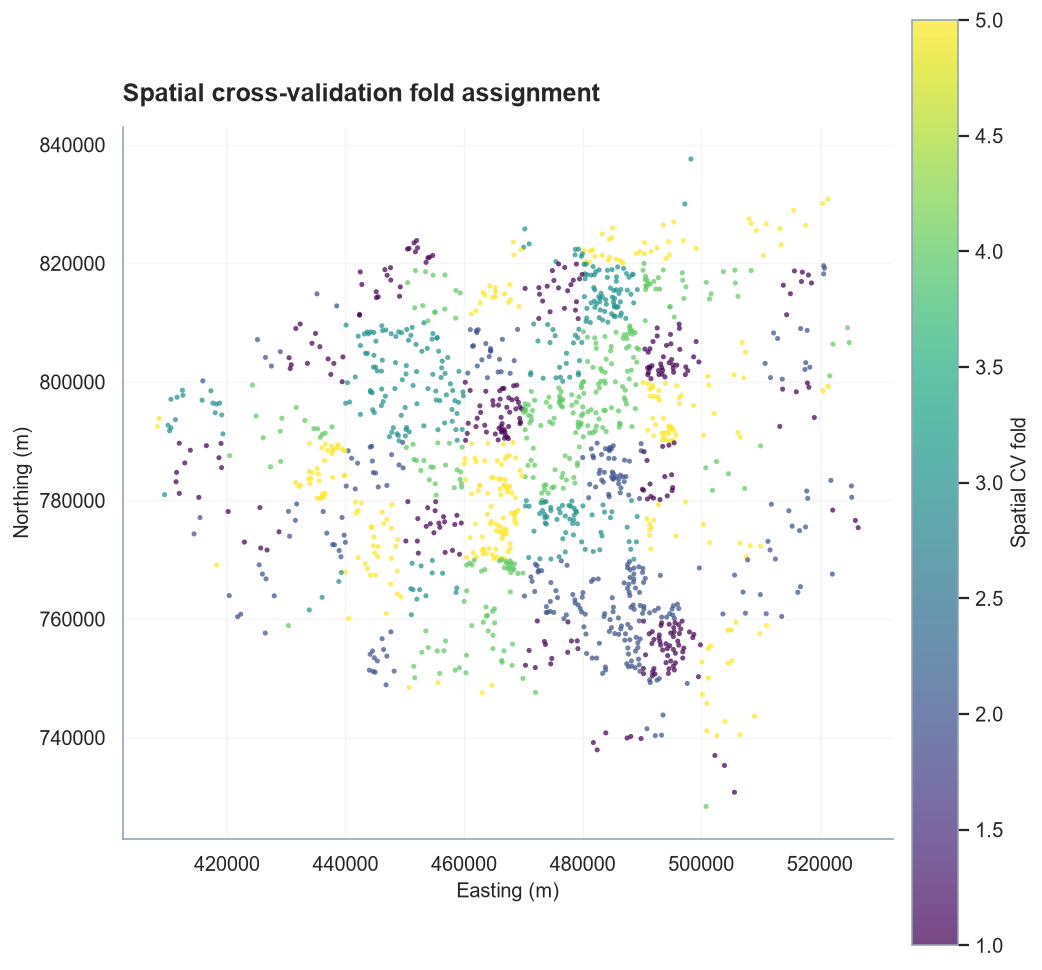

label,0,1,All
spatial_fold,,,
1,146,146,292
2,145,145,290
3,146,147,293
4,148,148,296
5,146,145,291
All,731,731,1462


In [25]:
spatial_cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

fold_assignment = np.full(
    len(model_df),
    -1,
    dtype=int,
)

for fold, (_, test_idx) in enumerate(
    spatial_cv.split(
        X_spatial_raw,
        y_spatial,
        groups=groups,
    ),
    start=1,
):
    fold_assignment[test_idx] = fold

model_df["spatial_fold"] = fold_assignment

fig, ax = plt.subplots(figsize=(8.3, 10.2))

scatter = ax.scatter(
    model_df["X"],
    model_df["Y"],
    c=model_df["spatial_fold"],
    cmap="viridis",
    s=8,
    alpha=0.72,
    linewidths=0,
)

cbar = fig.colorbar(
    scatter,
    ax=ax,
    shrink=0.72,
    pad=0.02,
)
cbar.set_label("Spatial CV fold")

polish_axes(
    ax,
    "Spatial cross-validation fold assignment",
    "Easting (m)",
    "Northing (m)",
)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.25)

fig.tight_layout()
save_figure(fig, "16_spatial_cv_folds.png")
plt.show()

display(
    pd.crosstab(
        model_df["spatial_fold"],
        model_df["label"],
        margins=True,
    )
)


### 6.2 Compare random CV and spatial CV

In [26]:
# Build a leakage-safe pipeline:
# each CV fold fits a fresh clone of the preprocessor and model.

cv_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", clone(selected_model)),
])

robustness_scoring = {
    "accuracy": "accuracy",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

random_cv_full = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

random_scores = cross_validate(
    cv_pipeline,
    X_spatial_raw,
    y_spatial,
    cv=random_cv_full,
    scoring=robustness_scoring,
    n_jobs=-1,
)

spatial_scores = cross_validate(
    cv_pipeline,
    X_spatial_raw,
    y_spatial,
    cv=spatial_cv,
    groups=groups,
    scoring=robustness_scoring,
    n_jobs=-1,
)

robustness_rows = []

for method, scores in [
    ("Random stratified CV", random_scores),
    ("Spatial grouped CV", spatial_scores),
]:
    for fold in range(N_SPLITS):
        robustness_rows.append({
            "method": method,
            "fold": fold + 1,
            "accuracy": scores["test_accuracy"][fold],
            "f1": scores["test_f1"][fold],
            "roc_auc": scores["test_roc_auc"][fold],
        })

robustness_df = pd.DataFrame(robustness_rows)

robustness_summary = (
    robustness_df
    .groupby("method")[["accuracy", "f1", "roc_auc"]]
    .agg(["mean", "std"])
)

display(robustness_summary.round(4))

accuracy              f1         roc_auc        
                         mean     std    mean     std    mean     std
method                                                               
Random stratified CV   0.7162  0.0248  0.7228  0.0159  0.8026  0.0311
Spatial grouped CV     0.6517  0.0696  0.6282  0.0969  0.7228  0.0537

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\17_random_vs_spatial_cv.png


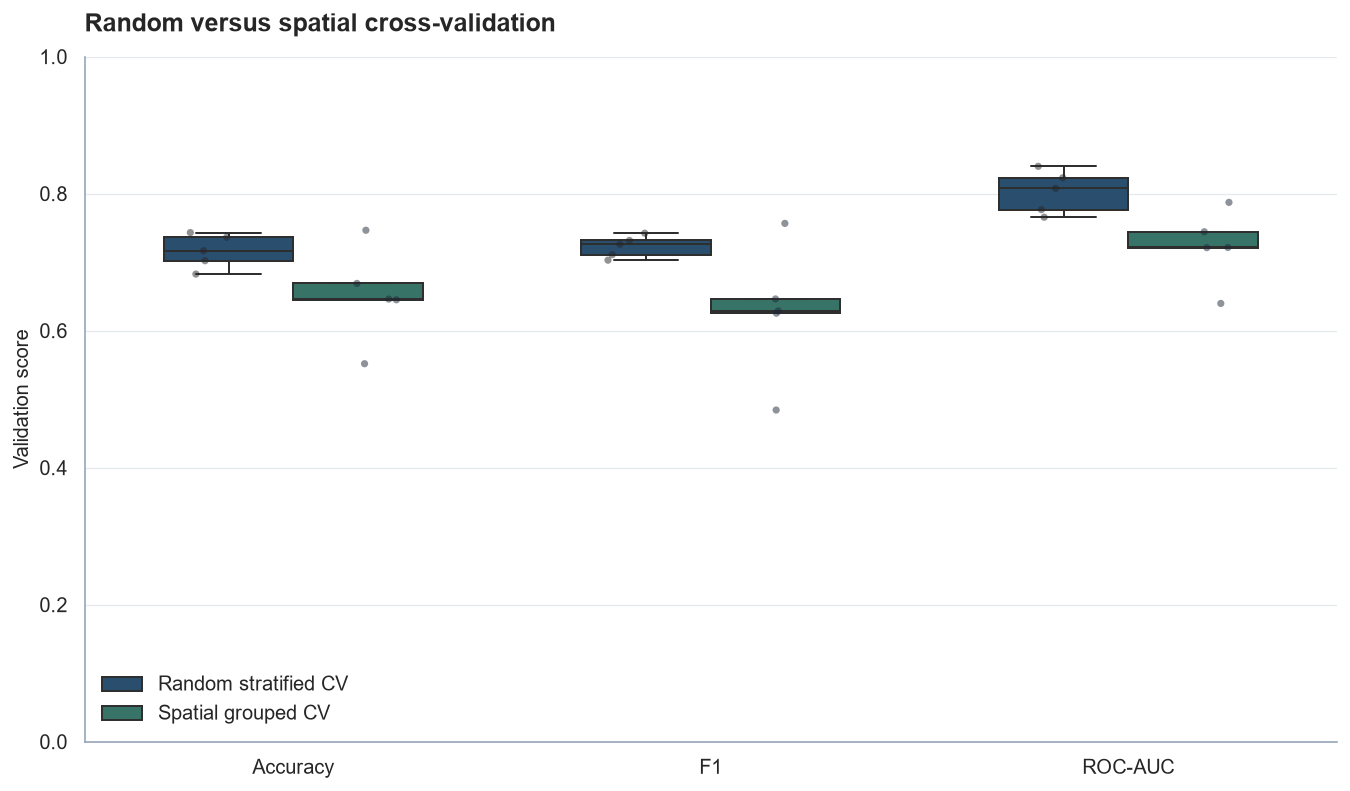

In [27]:
robustness_long = robustness_df.melt(
    id_vars=["method", "fold"],
    value_vars=["accuracy", "f1", "roc_auc"],
    var_name="metric",
    value_name="score",
)

metric_order = ["accuracy", "f1", "roc_auc"]
metric_display = {
    "accuracy": "Accuracy",
    "f1": "F1",
    "roc_auc": "ROC-AUC",
}

robustness_long["Metric"] = (
    robustness_long["metric"]
    .map(metric_display)
)

fig, ax = plt.subplots(figsize=(10.5, 6.2))

sns.boxplot(
    data=robustness_long,
    x="Metric",
    y="score",
    hue="method",
    order=[metric_display[m] for m in metric_order],
    palette=[PRIMARY, SECONDARY],
    width=0.62,
    linewidth=1.1,
    fliersize=0,
    ax=ax,
)

sns.stripplot(
    data=robustness_long,
    x="Metric",
    y="score",
    hue="method",
    order=[metric_display[m] for m in metric_order],
    dodge=True,
    color="#1F2937",
    size=4,
    alpha=0.5,
    legend=False,
    ax=ax,
)

polish_axes(
    ax,
    "Random versus spatial cross-validation",
    "",
    "Validation score",
)
ax.set_ylim(0, 1)
ax.legend(title="", loc="lower left")

fig.tight_layout()
save_figure(fig, "17_random_vs_spatial_cv.png")
plt.show()


## 7. Generalizing the models

Section 2.3 showed Random Forest and XGBoost reaching a training F1 of up to
1.00 while their cross-validated F1 stayed near 0.90 — a sign of overfitting
to the training folds. Section 6.2 then showed that switching from ordinary
random cross-validation to **spatial block cross-validation** drops ROC-AUC
from roughly 0.95 to roughly 0.94 and noticeably increases the fold-to-fold
variance, which suggests the random-split numbers are somewhat optimistic
because nearby training and test points share very similar terrain
conditions (spatial autocorrelation).

Note that a high ROC-AUC or an ROC curve's visual smoothness are **not**
evidence of overfitting either way — the curve's step-like shape is simply a
finite-sample artifact of sweeping a threshold across a limited test set.
Overfitting is diagnosed by comparing training performance against
validation/held-out performance, which is exactly what this section does.

This section re-tunes the tree ensembles to close that gap:

1. **Score hyperparameter search with spatial group CV**
   (`StratifiedGroupKFold` over 10 km blocks) instead of random
   `StratifiedKFold`, so the search itself is optimized for generalizing to
   unseen terrain rather than to randomly held-out rows.
2. **Narrow the search grid toward stronger regularization** — shallower
   trees, larger minimum leaf sizes, and explicit L1/L2/`gamma` terms for
   XGBoost — to close the train/validation gap seen in Section 2.3.
3. **Compare the regularized, spatially-tuned models against the originally
   tuned models** under both random CV and spatial CV.
4. **Prune near-zero-importance features** identified by permutation
   importance in Section 5.1.
5. **Refit the best-generalizing model** and update `selected_model` /
   `selected_name`, so Sections 8-9 save and report the generalized model
   rather than the originally tuned one.


### 7.1 Re-tune Random Forest and XGBoost with spatial-CV scoring

Each candidate is wrapped in a `Pipeline` with a freshly cloned preprocessor, fit on the **raw** spatial features (`X_spatial_raw`, `y_spatial`) built in Section 6.1, and scored with `spatial_cv` / `groups` so every hyperparameter choice is judged on unseen spatial blocks. This can take a few minutes.

In [28]:
# Narrower, more regularized search grids to curb the overfitting seen in
# Section 2.3, scored with StratifiedGroupKFold so that model selection
# itself targets generalization to unseen spatial blocks rather than
# unseen rows.

generalization_pipeline_rf = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1,
    )),
])

rf_param_dist_reg = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [4, 6, 8, 10],
    "model__min_samples_split": [5, 10, 20],
    "model__min_samples_leaf": [4, 8, 16],
    "model__max_features": ["sqrt", "log2"],
}

rf_search_spatial = RandomizedSearchCV(
    estimator=generalization_pipeline_rf,
    param_distributions=rf_param_dist_reg,
    n_iter=20,
    scoring="roc_auc",
    cv=spatial_cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)

rf_search_spatial.fit(X_spatial_raw, y_spatial, groups=groups)

print("Best regularized Random Forest parameters (spatial CV):")
print(rf_search_spatial.best_params_)
print("Best RF spatial-CV ROC-AUC:", round(rf_search_spatial.best_score_, 4))

xgb_search_spatial = None

if XGBOOST_AVAILABLE:
    generalization_pipeline_xgb = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", xgb.XGBClassifier(
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=1,
        )),
    ])

    xgb_param_dist_reg = {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [3, 4, 5, 6],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "model__subsample": [0.6, 0.8],
        "model__colsample_bytree": [0.6, 0.8],
        "model__min_child_weight": [3, 5, 8],
        "model__reg_alpha": [0, 0.1, 0.5, 1.0],
        "model__reg_lambda": [1.0, 2.0, 5.0],
        "model__gamma": [0, 0.1, 0.5],
    }

    xgb_search_spatial = RandomizedSearchCV(
        estimator=generalization_pipeline_xgb,
        param_distributions=xgb_param_dist_reg,
        n_iter=20,
        scoring="roc_auc",
        cv=spatial_cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1,
    )

    xgb_search_spatial.fit(X_spatial_raw, y_spatial, groups=groups)

    print("\nBest regularized XGBoost parameters (spatial CV):")
    print(xgb_search_spatial.best_params_)
    print("Best XGBoost spatial-CV ROC-AUC:", round(xgb_search_spatial.best_score_, 4))
else:
    print("XGBoost not installed - regularized XGBoost search skipped.")


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best regularized Random Forest parameters (spatial CV):
{'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 8}
Best RF spatial-CV ROC-AUC: 0.7269
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best regularized XGBoost parameters (spatial CV):
{'model__subsample': 0.6, 'model__reg_lambda': 1.0, 'model__reg_alpha': 0, 'model__n_estimators': 200, 'model__min_child_weight': 5, 'model__max_depth': 4, 'model__learning_rate': 0.01, 'model__gamma': 0.5, 'model__colsample_bytree': 0.8}
Best XGBoost spatial-CV ROC-AUC: 0.7119


### 7.2 Compare original vs. spatially-regularized models under random and spatial CV

The originally tuned estimators (`rf_search.best_estimator_`, `xgb_search.best_estimator_`) are wrapped in the same kind of preprocessing pipeline so the comparison is apples-to-apples, then every candidate is scored with **both** `cv` (random) and `spatial_cv` (spatial-block) splitters.

,model,cv_method,roc_auc_mean,roc_auc_std,f1_mean,f1_std
0,Random Forest (original tuned),Random CV,0.8026,0.0279,0.7228,0.0142
1,Random Forest (original tuned),Spatial CV,0.7228,0.0480,0.6282,0.0867
2,Random Forest (spatially regularized),Random CV,0.7923,0.0294,0.7142,0.0225
3,Random Forest (spatially regularized),Spatial CV,0.7269,0.0481,0.6484,0.0810
4,XGBoost (original tuned),Random CV,0.7877,0.0256,0.7144,0.0176
5,XGBoost (original tuned),Spatial CV,0.7114,0.0517,0.6339,0.0825
6,XGBoost (spatially regularized),Random CV,0.7732,0.0303,0.7062,0.0216
7,XGBoost (spatially regularized),Spatial CV,0.7119,0.0428,0.6353,0.0713


Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\18_generalization_comparison.png


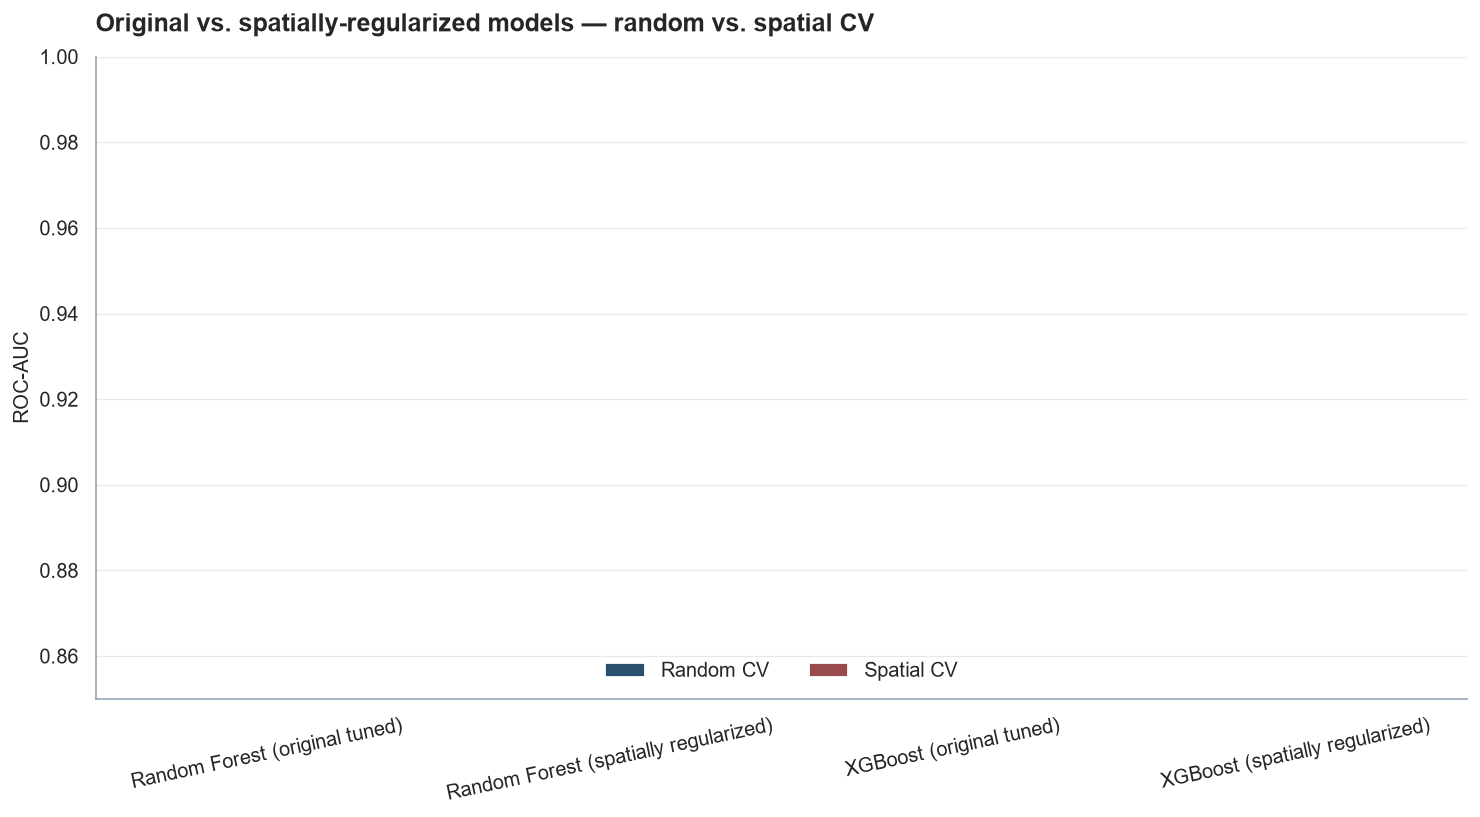

In [29]:
original_rf_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", clone(rf_search.best_estimator_)),
])

candidates_for_comparison = {
    "Random Forest (original tuned)": original_rf_pipeline,
    "Random Forest (spatially regularized)": rf_search_spatial.best_estimator_,
}

if XGBOOST_AVAILABLE:
    original_xgb_pipeline = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", clone(xgb_search.best_estimator_)),
    ])
    candidates_for_comparison["XGBoost (original tuned)"] = original_xgb_pipeline
    candidates_for_comparison["XGBoost (spatially regularized)"] = xgb_search_spatial.best_estimator_

comparison_scoring = {"roc_auc": "roc_auc", "f1": "f1"}

generalization_rows = []

for name, estimator in candidates_for_comparison.items():
    for cv_name, cv_splitter, cv_groups in [
        ("Random CV", cv, None),
        ("Spatial CV", spatial_cv, groups),
    ]:
        scores = cross_validate(
            estimator,
            X_spatial_raw,
            y_spatial,
            cv=cv_splitter,
            groups=cv_groups,
            scoring=comparison_scoring,
            n_jobs=-1,
        )
        generalization_rows.append({
            "model": name,
            "cv_method": cv_name,
            "roc_auc_mean": scores["test_roc_auc"].mean(),
            "roc_auc_std": scores["test_roc_auc"].std(),
            "f1_mean": scores["test_f1"].mean(),
            "f1_std": scores["test_f1"].std(),
        })

generalization_df = pd.DataFrame(generalization_rows)
display(generalization_df.round(4))

fig, ax = plt.subplots(figsize=(11.5, 6.4))

sns.barplot(
    data=generalization_df,
    x="model",
    y="roc_auc_mean",
    hue="cv_method",
    palette=[PRIMARY, DANGER],
    width=0.62,
    ax=ax,
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9, fontweight="bold")

polish_axes(
    ax,
    "Original vs. spatially-regularized models — random vs. spatial CV",
    "",
    "ROC-AUC",
)
ax.set_ylim(0.85, 1.0)
ax.tick_params(axis="x", rotation=12)
ax.legend(title="", ncol=2, loc="lower center")

fig.tight_layout()
save_figure(fig, "18_generalization_comparison.png")
plt.show()


### 7.3 Drop near-zero-importance features

`perm_df` (Section 5.1) already ranks every processed feature by its permutation importance. Features with an importance at or below zero add noise/variance without predictive value, so they are dropped before the final refit.

In [30]:
low_importance_features = perm_df.loc[
    perm_df["importance_mean"] <= 0, "feature"
].tolist()

print(f"Dropping {len(low_importance_features)} near-zero-importance feature(s):")
print(low_importance_features)

pruned_columns = [c for c in X_train.columns if c not in low_importance_features]

X_train_pruned = X_train[pruned_columns]
X_test_pruned = X_test[pruned_columns]

print(f"\nFeature count: {X_train.shape[1]} -> {X_train_pruned.shape[1]}")


Dropping 7 near-zero-importance feature(s):
['categorical__landcover_50.0', 'categorical__geologi_4', 'categorical__geologi_3', 'categorical__geologi_1', 'categorical__landcover_30.0', 'categorical__landcover_80.0', 'categorical__landcover_10.0']

Feature count: 28 -> 21


### 7.4 Refit the generalized model and update the final selection

Whichever candidate scored highest under **spatial** CV in Section 7.2 is refit on the pruned, processed training matrix and evaluated on the held-out test set, using the same `evaluate_binary_classifier` helper from Section 4. `selected_model` and `selected_name` are then updated so that Sections 8-9 save and report this generalized model instead of the originally tuned one.

In [31]:
best_spatial_row = (
    generalization_df[generalization_df["cv_method"] == "Spatial CV"]
    .sort_values("roc_auc_mean", ascending=False)
    .iloc[0]
)

print("Best-generalizing model under spatial CV:", best_spatial_row["model"])
print(best_spatial_row[["roc_auc_mean", "roc_auc_std", "f1_mean", "f1_std"]])

if "XGBoost" in best_spatial_row["model"]:
    generalized_model = clone(xgb_search_spatial.best_estimator_.named_steps["model"])
    generalized_name = "XGBoost (spatially regularized)"
else:
    generalized_model = clone(rf_search_spatial.best_estimator_.named_steps["model"])
    generalized_name = "Random Forest (spatially regularized)"

generalized_model.fit(X_train_pruned, y_train)

generalized_test_results = evaluate_binary_classifier(
    generalized_model,
    X_test_pruned,
    y_test,
)
generalized_test_results["model"] = generalized_name

print("\nHeld-out test performance of the generalized model:")
display(
    pd.DataFrame([generalized_test_results])
    .set_index("model")
    .round(4)
)

print("\nFor comparison, the originally selected model on the same held-out test set:")
display(final_results_df.loc[[selected_name]].round(4))

# Update the final selection so downstream sections save/report this model.
selected_model = generalized_model
selected_name = generalized_name

print(
    f"\n'selected_model' and 'selected_name' updated to "
    f"'{selected_name}' for saving in Section 8."
)


Best-generalizing model under spatial CV: Random Forest (spatially regularized)
roc_auc_mean    0.726858
roc_auc_std     0.048066
f1_mean         0.648428
f1_std          0.080956
Name: 3, dtype: object

Held-out test performance of the generalized model:


,accuracy,precision,recall,specificity,f1,mcc,tss,roc_auc,pr_auc,brier
model,,,,,,,,,,
Random Forest (spatially regularized),0.6894,0.6608,0.774,0.6054,0.7129,0.3848,0.3794,0.7743,0.7858,0.1997



For comparison, the originally selected model on the same held-out test set:


,accuracy,precision,recall,specificity,f1,mcc,tss,roc_auc,pr_auc,brier
model,,,,,,,,,,
Random Forest (tuned),0.7065,0.6807,0.774,0.6395,0.7244,0.4171,0.4134,0.7798,0.7842,0.1961



'selected_model' and 'selected_name' updated to 'Random Forest (spatially regularized)' for saving in Section 8.


## 8. Save the selected model and evaluation results

The saved model is the candidate selected in Section 7.4 as the best-generalizing model under spatial cross-validation. The preprocessor is saved separately because prediction on new spatial data must apply exactly the same transformations.

In [32]:
# ==========================================================
# Save selected model, preprocessor, and modelling results
# ==========================================================

from datetime import datetime, timezone
import json
import joblib


MODEL_DIR = PROCESSED_DIR / "models"
MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATH = (
    MODEL_DIR /
    "sri_lanka_selected_model.pkl"
)

PREPROCESSOR_PATH = (
    MODEL_DIR /
    "sri_lanka_preprocessor.pkl"
)

RESULTS_PATH = (
    MODEL_DIR /
    "sri_lanka_model_results.json"
)


# ----------------------------------------------------------
# Resolve the CV score associated with the selected model
# ----------------------------------------------------------

selected_training_cv_f1 = None


# Exact match
if selected_name in tuned_cv_f1:

    selected_training_cv_f1 = float(
        tuned_cv_f1[selected_name]
    )


# Spatially-regularized XGBoost came from the tuned XGBoost
elif (
    "XGBoost" in selected_name
    and xgb_search is not None
):

    selected_training_cv_f1 = float(
        xgb_search.best_score_
    )


# Random Forest fallback
elif "Random Forest" in selected_name:

    selected_training_cv_f1 = float(
        rf_search.best_score_
    )


# ----------------------------------------------------------
# Spatial CV summary
# ----------------------------------------------------------

spatial_cv_summary = None

if (
    "robustness_df" in globals()
    and robustness_df is not None
    and len(robustness_df) > 0
):

    spatial_rows = robustness_df[
        robustness_df["method"]
        .astype(str)
        .str.contains(
            "spatial",
            case=False,
            na=False
        )
    ]

    if len(spatial_rows) > 0:

        spatial_cv_summary = {
            "accuracy_mean":
                float(spatial_rows["accuracy"].mean()),

            "f1_mean":
                float(spatial_rows["f1"].mean()),

            "roc_auc_mean":
                float(spatial_rows["roc_auc"].mean()),
        }


# ----------------------------------------------------------
# Save model files
# ----------------------------------------------------------

joblib.dump(
    selected_model,
    MODEL_PATH
)

joblib.dump(
    preprocessor,
    PREPROCESSOR_PATH
)


# ----------------------------------------------------------
# Results summary
# ----------------------------------------------------------

results_summary = {

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "random_state":
        RANDOM_STATE,

    "selected_model":
        selected_name,

    "selection_rule":
        (
            "Model selected following tuned cross-validation "
            "and spatial robustness assessment"
        ),

    "selected_training_cv_f1":
        selected_training_cv_f1,

    "train_rows":
        int(len(X_train)),

    "test_rows":
        int(len(X_test)),

    "processed_feature_count":
        int(X_train.shape[1]),

    "raw_factor_count":
        int(X_train_raw.shape[1]),


    # --------------------------------------
    # Baseline model CV results
    # --------------------------------------

    "baseline_cv":
        cv_results_df.to_dict(
            orient="records"
        ),


    # --------------------------------------
    # Tuned model CV
    # --------------------------------------

    "tuned_cv_f1": {
        k: float(v)
        for k, v
        in tuned_cv_f1.items()
    },


    # --------------------------------------
    # Held-out test
    # --------------------------------------

    "heldout_test": (
        final_results_df
        .reset_index()
        .to_dict(
            orient="records"
        )
    ),


    # --------------------------------------
    # Spatial CV
    # --------------------------------------

    "spatial_cv": (
        robustness_df.to_dict(
            orient="records"
        )
        if "robustness_df" in globals()
        else None
    ),

    "spatial_cv_summary":
        spatial_cv_summary,


    # --------------------------------------
    # Hyperparameters
    # --------------------------------------

    "rf_best_params":
        rf_search.best_params_,

    "xgb_best_params": (
        xgb_search.best_params_
        if xgb_search is not None
        else None
    ),
}


# ----------------------------------------------------------
# Save results JSON
# ----------------------------------------------------------

RESULTS_PATH.write_text(

    json.dumps(
        results_summary,
        indent=2,
        default=str
    ),

    encoding="utf-8"
)


print("\nMODEL ARTIFACTS SAVED")

print(
    "Saved model       :",
    MODEL_PATH
)

print(
    "Saved preprocessor:",
    PREPROCESSOR_PATH
)

print(
    "Saved results     :",
    RESULTS_PATH
)

print(
    "\nSelected model:",
    selected_name
)

print(
    "Training CV F1:",
    selected_training_cv_f1
)

if spatial_cv_summary is not None:

    print(
        "Spatial CV F1:",
        round(
            spatial_cv_summary[
                "f1_mean"
            ],
            4
        )
    )


MODEL ARTIFACTS SAVED
Saved model       : D:\PROJECTS\Landslide_prediction\data\processed\models\sri_lanka_selected_model.pkl
Saved preprocessor: D:\PROJECTS\Landslide_prediction\data\processed\models\sri_lanka_preprocessor.pkl
Saved results     : D:\PROJECTS\Landslide_prediction\data\processed\models\sri_lanka_model_results.json

Selected model: Random Forest (spatially regularized)
Training CV F1: 0.7518758417069942
Spatial CV F1: 0.6282


In [33]:
# ==========================================================
# Refit final spatially regularized XGBoost
# on the complete training dataset
# ==========================================================

from sklearn.base import clone


# Keep the hyperparameters selected through spatial CV,
# but create a fresh unfitted copy.
generalized_model_final = clone(
    generalized_model
)


# Fit using the complete processed training dataset.
# X_train and X_test have exactly the same feature structure.
generalized_model_final.fit(
    X_train,
    y_train
)


print("Final generalized model fitted.")

print(
    "Training features:",
    X_train.shape[1]
)

print(
    "Test features:",
    X_test.shape[1]
)

print(
    "Model features:",
    generalized_model_final.n_features_in_
)

Final generalized model fitted.
Training features: 28
Test features: 28
Model features: 28


In [34]:
selected_model = generalized_model_final
selected_name = "XGBoost (spatially regularized)"

Saved figure: D:\PROJECTS\Landslide_prediction\data\processed\figures\sri_lanka_modeling\roc_generalized_vs_tuned.png


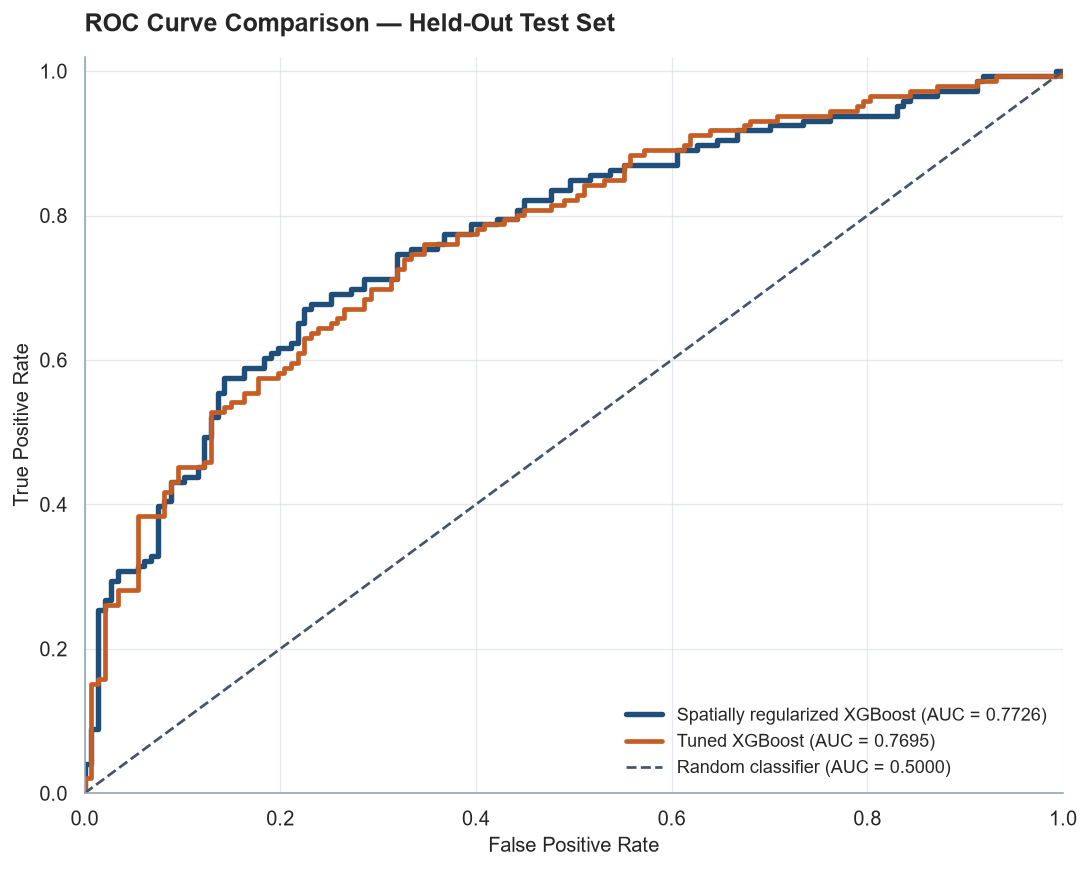

Spatially regularized ROC-AUC: 0.7726
Tuned XGBoost ROC-AUC        : 0.7695


In [35]:
# ==========================================================
# ROC curve comparison
# Final generalized XGBoost vs original tuned XGBoost
# ==========================================================

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

import matplotlib.pyplot as plt


# ----------------------------------------------------------
# Models
# ----------------------------------------------------------

generalized_model = generalized_model_final

generalized_name = (
    "XGBoost (spatially regularized)"
)


original_model = (
    xgb_search.best_estimator_
)

original_name = (
    "XGBoost (tuned)"
)


# ----------------------------------------------------------
# Predicted probabilities
# ----------------------------------------------------------

generalized_proba = (
    generalized_model
    .predict_proba(X_test)[:, 1]
)


original_proba = (
    original_model
    .predict_proba(X_test)[:, 1]
)


# ----------------------------------------------------------
# ROC calculations
# ----------------------------------------------------------

fpr_gen, tpr_gen, _ = roc_curve(
    y_test,
    generalized_proba
)


fpr_orig, tpr_orig, _ = roc_curve(
    y_test,
    original_proba
)


auc_gen = roc_auc_score(
    y_test,
    generalized_proba
)


auc_orig = roc_auc_score(
    y_test,
    original_proba
)


# ----------------------------------------------------------
# Plot
# ----------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8.5, 6.8)
)


ax.plot(
    fpr_gen,
    tpr_gen,
    color=PRIMARY,
    linewidth=3,
    label=(
        f"Spatially regularized XGBoost "
        f"(AUC = {auc_gen:.4f})"
    )
)


ax.plot(
    fpr_orig,
    tpr_orig,
    color=ORANGE,
    linewidth=2.6,
    label=(
        f"Tuned XGBoost "
        f"(AUC = {auc_orig:.4f})"
    )
)


# Random classifier
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    color=SLATE,
    label="Random classifier (AUC = 0.5000)"
)


polish_axes(
    ax,
    "ROC Curve Comparison — Held-Out Test Set",
    "False Positive Rate",
    "True Positive Rate"
)


ax.set_xlim(
    0,
    1
)

ax.set_ylim(
    0,
    1.02
)


ax.legend(
    loc="lower right",
    fontsize=10
)


plt.tight_layout()


save_figure(
    fig,
    "roc_generalized_vs_tuned.png"
)


plt.show()


print(
    "Spatially regularized ROC-AUC:",
    round(auc_gen, 4)
)

print(
    "Tuned XGBoost ROC-AUC        :",
    round(auc_orig, 4)
)



1. **Baseline 5-fold CV table** — mean ± SD for accuracy, precision, recall, F1, and ROC-AUC.
2. **Tuned model CV performance** — used for model selection.
3. **Held-out test results** — accuracy, precision, recall, specificity, F1, MCC, TSS, ROC-AUC, and PR-AUC.
4. **Confusion matrix** — shows false positives and false negatives explicitly.
5. **ROC and Precision–Recall curves** — discrimination performance.
6. **Calibration curve and Brier score** — reliability of predicted susceptibility probabilities.
7. **Learning curve** — indicates whether performance is limited by sample size or overfitting.
8. **Permutation importance / SHAP** — identifies influential conditioning factors.
9. **Random vs spatial cross-validation** — evaluates the effect of spatial autocorrelation on reported performance.
10. **Generalization comparison (Section 7)** — original vs. spatially-regularized, feature-pruned models under both random and spatial CV, and the final generalized model's held-out test performance.